# Section 0 – Setup

In [1]:
!pip -q install rdkit PyTDC scikit-learn xgboost seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.2/154.2 kB 10.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 96.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.3/151.3 kB 17.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 113.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (pyproject.toml) ... error
error: metadata-generation-failed

× En

In [1]:
!pip -q install rdkit scikit-learn xgboost seaborn fuzzywuzzy huggingface_hub openpyxl tqdm requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 55.3 MB/s eta 0:00:00


In [2]:
!pip -q install PyTDC --no-deps

  Preparing metadata (setup.py) ... done


In [3]:
import rdkit
from tdc.single_pred import Tox
print("rdkit", rdkit.__version__)
print("PyTDC OK")

rdkit 2026.03.6
PyTDC OK


In [4]:
#@title 0.2 Drive, folders, seeds, helper functions { display-mode: "form" }
import os, random, zipfile, json, glob, warnings
import numpy as np
from google.colab import drive, files
warnings.filterwarnings("ignore")

drive.mount('/content/drive')
ROOT = '/content/drive/MyDrive/AI IN DRUG DISCOVERY/MINI PROJECT'
for s in ['data', 'splits', 'models', 'figures', 'results', 'downloads']:
    os.makedirs(f'{ROOT}/{s}', exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

def save_fig(fig, name):
    path = f'{ROOT}/figures/{name}.png'
    fig.savefig(path, dpi=300, bbox_inches='tight')
    return path

def package_section(tag, paths):
    """Zip the given files/folders (relative structure preserved) and download to your PC."""
    zpath = f'{ROOT}/downloads/{tag}.zip'
    with zipfile.ZipFile(zpath, 'w', zipfile.ZIP_DEFLATED) as z:
        for p in paths:
            if os.path.isdir(p):
                for r, _, fs in os.walk(p):
                    for f in fs:
                        fp = os.path.join(r, f)
                        z.write(fp, os.path.relpath(fp, ROOT))
            elif os.path.exists(p):
                z.write(p, os.path.relpath(p, ROOT))
    print('Packaged:', zpath)
    files.download(zpath)

def write_requirements(pkgs):
    from importlib.metadata import version, PackageNotFoundError
    lines = []
    for p in pkgs:
        try: lines.append(f'{p}=={version(p)}')
        except PackageNotFoundError: pass
    with open(f'{ROOT}/requirements.txt', 'w') as f:
        f.write('\n'.join(lines))
    print('\n'.join(lines))

write_requirements(['rdkit', 'PyTDC', 'scikit-learn', 'xgboost', 'numpy', 'pandas',
                    'matplotlib', 'seaborn', 'scipy'])
print('\nROOT =', ROOT)

Mounted at /content/drive
rdkit==2026.3.6
PyTDC==1.1.15
scikit-learn==1.6.1
xgboost==3.4.1
numpy==2.1.3
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2
scipy==1.16.3

ROOT = /content/drive/MyDrive/AI IN DRUG DISCOVERY/MINI PROJECT


In [5]:
#@title 1.1 Load raw TDC data + official split { display-mode: "form" }
import pandas as pd
from tdc.single_pred import Tox

data = Tox(name='Carcinogens_Lagunin', path=f'{ROOT}/data/tdc_raw')
raw = data.get_data()
print('Raw shape:', raw.shape)
print(raw.head())
print('\nClass counts (1 = carcinogen):\n', raw['Y'].value_counts())
raw.to_csv(f'{ROOT}/data/raw_carcinogens_lagunin.csv', index=False)

# TDC's default split is RANDOM (seed 42), not scaffold
official = data.get_split()
for k, v in official.items():
    print(k, v.shape, 'carcinogen fraction =', round(v.Y.mean(), 3))
    v.to_csv(f'{ROOT}/splits/tdc_official_{k}.csv', index=False)

Downloading...
100%|██████████| 20.2k/20.2k [00:00<00:00, 1.40MiB/s]
Loading...
Done!


Raw shape: (280, 3)
  Drug_ID                                               Drug  Y
0  Drug_1                                    CC(CCl)OC(C)CCl  1
1  Drug_2                   COc1ccc(C(=O)/C(Br)=C\C(=O)O)cc1  1
2  Drug_3  O=S(=O)(O)c1cc(S(=O)(=O)O)c2c(/N=N/c3ccccc3)c(...  1
3  Drug_4  O=S(=O)(O)c1ccc(/N=N/c2cc(S(=O)(=O)O)c3ccccc3c...  1
4  Drug_5                                        ClCc1ccccn1  1

Class counts (1 = carcinogen):
 Y
0    220
1     60
Name: count, dtype: int64
train (196, 3) carcinogen fraction = 0.214
valid (28, 3) carcinogen fraction = 0.214
test (56, 3) carcinogen fraction = 0.214


In [6]:
#@title 1.2 Curate: standardize, canonicalize, de-duplicate { display-mode: "form" }
from rdkit import Chem, RDLogger
from rdkit.Chem.MolStandardize import rdMolStandardize
RDLogger.DisableLog('rdApp.*')

chooser, uncharger = rdMolStandardize.LargestFragmentChooser(), rdMolStandardize.Uncharger()

def standardize(smi):
    m = Chem.MolFromSmiles(smi)
    if m is None: return None
    try:
        m = chooser.choose(m)            # strip salts / keep largest fragment
        m = uncharger.uncharge(m)
        Chem.SanitizeMol(m)
        if not any(a.GetSymbol() == 'C' for a in m.GetAtoms()):   # drop inorganics
            return None
        return Chem.MolToSmiles(m, isomericSmiles=False)          # canonical, non-stereo
    except Exception:
        return None

df = raw.copy()
log = {'n_raw': len(df)}
df['smiles_can'] = df['Drug'].apply(standardize)
log['n_invalid_or_inorganic'] = int(df['smiles_can'].isna().sum())
df = df.dropna(subset=['smiles_can'])

# Duplicates: conflicting labels are removed, consistent duplicates collapsed to one row
g = df.groupby('smiles_can')['Y'].agg(['nunique', 'count'])
conflicts = g[g['nunique'] > 1].index
consistent = g[g['nunique'] == 1]
log['n_conflicting_label_smiles'] = int(len(conflicts))
log['n_consistent_duplicate_rows_removed'] = int((consistent['count'] - 1).sum())
df = df[~df['smiles_can'].isin(conflicts)].drop_duplicates('smiles_can').reset_index(drop=True)

df = df.rename(columns={'Drug_ID': 'name', 'Y': 'label'})[['name', 'smiles_can', 'label']]
log['n_final'] = len(df)
log['n_carcinogen'] = int(df.label.sum())
log['n_non_carcinogen'] = int((df.label == 0).sum())
log['carcinogen_fraction'] = round(float(df.label.mean()), 4)

# Leakage audit: do TDC's official splits share molecules after standardization?
sm = {k: set(v['Drug'].apply(standardize).dropna()) for k, v in official.items()}
log['official_overlap_train_test'] = len(sm['train'] & sm['test'])
log['official_overlap_train_valid'] = len(sm['train'] & sm['valid'])
log['official_overlap_valid_test'] = len(sm['valid'] & sm['test'])

df.to_csv(f'{ROOT}/data/curated_carcinogens.csv', index=False)
json.dump(log, open(f'{ROOT}/results/s1_curation_log.json', 'w'), indent=2)
print(json.dumps(log, indent=2))

{
  "n_raw": 280,
  "n_invalid_or_inorganic": 0,
  "n_conflicting_label_smiles": 2,
  "n_consistent_duplicate_rows_removed": 2,
  "n_final": 274,
  "n_carcinogen": 58,
  "n_non_carcinogen": 216,
  "carcinogen_fraction": 0.2117,
  "official_overlap_train_test": 1,
  "official_overlap_train_valid": 3,
  "official_overlap_valid_test": 0
}


{'unique_scaffolds': 184, 'singleton_scaffolds': 148, 'acyclic_molecules': 19, 'largest_scaffold_group': 19}


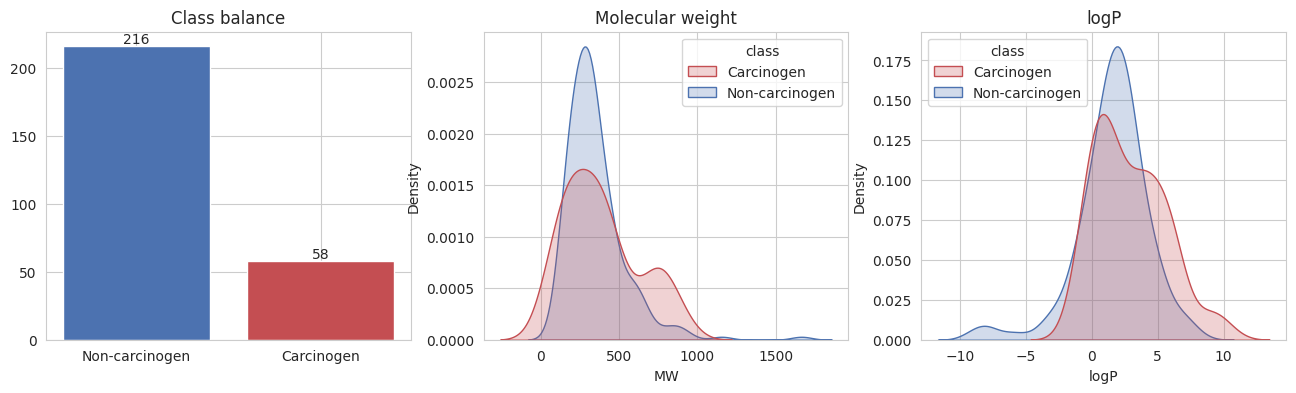

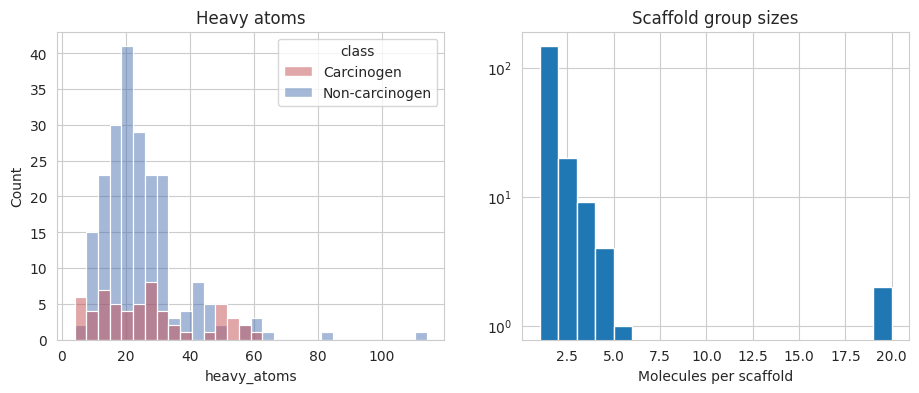

In [7]:
#@title 1.3 EDA: class balance, properties, scaffolds { display-mode: "form" }
import matplotlib.pyplot as plt, seaborn as sns
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors
from rdkit.Chem.Scaffolds import MurckoScaffold

df = pd.read_csv(f'{ROOT}/data/curated_carcinogens.csv')
mols = [Chem.MolFromSmiles(s) for s in df.smiles_can]
df['class'] = df.label.map({0: 'Non-carcinogen', 1: 'Carcinogen'})
df['MW'] = [Descriptors.MolWt(m) for m in mols]
df['logP'] = [Crippen.MolLogP(m) for m in mols]
df['heavy_atoms'] = [m.GetNumHeavyAtoms() for m in mols]
df['n_rings'] = [rdMolDescriptors.CalcNumRings(m) for m in mols]
df['scaffold'] = [MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in mols]

sc = df['scaffold'].value_counts()
scaf_stats = {'unique_scaffolds': int(len(sc)),
              'singleton_scaffolds': int((sc == 1).sum()),
              'acyclic_molecules': int((df.scaffold == '').sum()),
              'largest_scaffold_group': int(sc.iloc[0])}
json.dump(scaf_stats, open(f'{ROOT}/results/s1_scaffold_stats.json', 'w'), indent=2)
print(scaf_stats)

pal = {'Non-carcinogen': '#4C72B0', 'Carcinogen': '#C44E52'}
sns.set_style('whitegrid')

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
counts = df['class'].value_counts()
ax[0].bar(counts.index, counts.values, color=[pal[c] for c in counts.index])
ax[0].set_title('Class balance')
for i, v in enumerate(counts.values): ax[0].text(i, v + 2, str(v), ha='center')
sns.kdeplot(data=df, x='MW', hue='class', palette=pal, fill=True, common_norm=False, ax=ax[1]); ax[1].set_title('Molecular weight')
sns.kdeplot(data=df, x='logP', hue='class', palette=pal, fill=True, common_norm=False, ax=ax[2]); ax[2].set_title('logP')
save_fig(fig, 's1_eda_class_properties'); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x='heavy_atoms', hue='class', palette=pal, bins=30, ax=ax[0]); ax[0].set_title('Heavy atoms')
ax[1].hist(sc.values, bins=range(1, sc.max() + 2)); ax[1].set_yscale('log')
ax[1].set_title('Scaffold group sizes'); ax[1].set_xlabel('Molecules per scaffold')
save_fig(fig, 's1_eda_heavyatoms_scaffolds'); plt.show()

df.to_csv(f'{ROOT}/data/curated_carcinogens_with_props.csv', index=False)

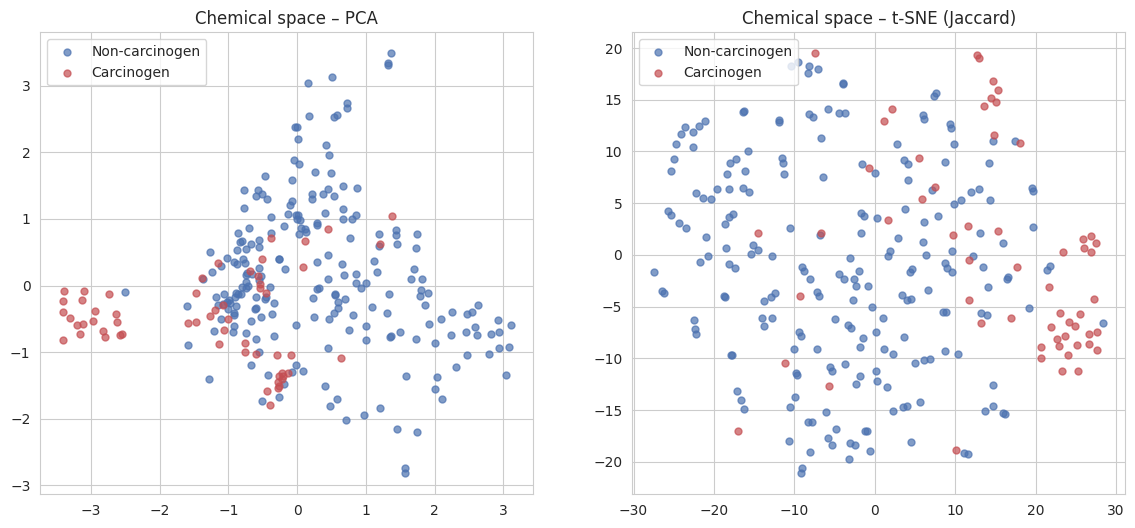

In [8]:
#@title 1.4 Chemical space: PCA and t-SNE on Morgan fingerprints { display-mode: "form" }
from rdkit.Chem import rdFingerprintGenerator
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X = np.vstack([gen.GetFingerprintAsNumPy(m) for m in mols]).astype(np.uint8)

pca = PCA(n_components=2, random_state=SEED).fit_transform(X)
tsne = TSNE(n_components=2, metric='jaccard', perplexity=30, init='random',
            random_state=SEED).fit_transform(X.astype(bool))

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, emb, t in zip(ax, [pca, tsne], ['PCA', 't-SNE (Jaccard)']):
    for name, col in pal.items():
        idx = (df['class'] == name).values
        a.scatter(emb[idx, 0], emb[idx, 1], s=25, alpha=0.7, c=col, label=name)
    a.set_title(f'Chemical space – {t}'); a.legend()
save_fig(fig, 's1_chemical_space'); plt.show()

In [9]:
print(open(f'{ROOT}/results/s1_scaffold_stats.json').read())

{
  "unique_scaffolds": 184,
  "singleton_scaffolds": 148,
  "acyclic_molecules": 19,
  "largest_scaffold_group": 19
}


In [10]:
#@title 1.5 Save + download Section 1 outputs { display-mode: "form" }
package_section('section1_data_eda', [
    f'{ROOT}/data/curated_carcinogens.csv',
    f'{ROOT}/data/curated_carcinogens_with_props.csv',
    f'{ROOT}/data/raw_carcinogens_lagunin.csv',
    f'{ROOT}/splits',
    f'{ROOT}/results',
    f'{ROOT}/requirements.txt',
    *glob.glob(f'{ROOT}/figures/s1_*.png'),
])

Packaged: /content/drive/MyDrive/AI IN DRUG DISCOVERY/MINI PROJECT/downloads/section1_data_eda.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
#@title 2.1 Build all splits (random CV, scaffold CV, fixed holdouts) { display-mode: "form" }
import numpy as np, pandas as pd, json
from sklearn.model_selection import StratifiedGroupKFold, RepeatedStratifiedKFold, train_test_split

df = pd.read_csv(f'{ROOT}/data/curated_carcinogens_with_props.csv')
y = df.label.values
scaf = df.scaffold.fillna('')
# each acyclic molecule becomes its own group so they spread across folds
df['group'] = [s if s != '' else f'ACYC_{i}' for i, s in enumerate(scaf)]
groups = df['group'].values
idx_all = np.arange(len(df))

def recs(pairs):
    return [{'repeat': k // 5, 'fold': k % 5, 'train': tr.tolist(), 'test': te.tolist()}
            for k, (tr, te) in enumerate(pairs)]

# 1) Random stratified CV: 5 folds x 5 repeats
rand_cv = recs(list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(idx_all, y)))

# 2) Scaffold-grouped stratified CV: 5 folds x 5 repeats
pairs = []
for rep in range(5):
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + rep)
    pairs += list(sgkf.split(idx_all, y, groups))
scaf_cv = recs(pairs)

json.dump(rand_cv, open(f'{ROOT}/splits/cv_random_5x5.json', 'w'))
json.dump(scaf_cv, open(f'{ROOT}/splits/cv_scaffold_5x5.json', 'w'))

# 3) Fixed scaffold holdout (about 70/10/20)
trv, te = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(idx_all, y, groups))
sub_tr, sub_va = next(StratifiedGroupKFold(7, shuffle=True, random_state=SEED).split(trv, y[trv], groups[trv]))
tr, va = trv[sub_tr], trv[sub_va]

# 4) Fixed random holdout with the same sizes (for comparison)
r_trv, r_te = train_test_split(idx_all, test_size=len(te), stratify=y, random_state=SEED)
r_tr, r_va = train_test_split(r_trv, test_size=len(va), stratify=y[r_trv], random_state=SEED)

df['scaffold_split'] = ''
df.loc[tr, 'scaffold_split'] = 'train'; df.loc[va, 'scaffold_split'] = 'valid'; df.loc[te, 'scaffold_split'] = 'test'
df['random_split'] = ''
df.loc[r_tr, 'random_split'] = 'train'; df.loc[r_va, 'random_split'] = 'valid'; df.loc[r_te, 'random_split'] = 'test'

keep = ['name', 'smiles_can', 'label', 'group', 'scaffold_split', 'random_split']
df[keep].to_csv(f'{ROOT}/splits/holdout_splits.csv', index=False)
for col, tag in [('scaffold_split', 'scaffold'), ('random_split', 'random')]:
    for part in ['train', 'valid', 'test']:
        df[df[col] == part][['name', 'smiles_can', 'label']].to_csv(f'{ROOT}/splits/{tag}_{part}.csv', index=False)

# Leakage audit
def audit(cv, by_group):
    for r in cv:
        tr_i, te_i = np.array(r['train']), np.array(r['test'])
        assert not set(df.smiles_can[tr_i]) & set(df.smiles_can[te_i]), 'molecule leakage'
        if by_group:
            assert not set(groups[tr_i]) & set(groups[te_i]), 'scaffold leakage'
audit(rand_cv, False); audit(scaf_cv, True)
for col in ['scaffold_split', 'random_split']:
    a, b = set(df[df[col] == 'train'].smiles_can), set(df[df[col] == 'test'].smiles_can)
    assert not a & b
assert not set(groups[tr]) & set(groups[te]) and not set(groups[trv]) & set(groups[te])
print('Leakage audit PASSED (no shared molecules; no shared scaffolds in scaffold splits)\n')

print('Scaffold holdout sizes / carcinogens:')
for p in ['train', 'valid', 'test']:
    s = df[df.scaffold_split == p]; print(f'  {p:5s} n={len(s):3d}  carcinogens={s.label.sum():2d}  ({s.label.mean():.2f})')
print('Random holdout sizes / carcinogens:')
for p in ['train', 'valid', 'test']:
    s = df[df.random_split == p]; print(f'  {p:5s} n={len(s):3d}  carcinogens={s.label.sum():2d}  ({s.label.mean():.2f})')
tc = [int(y[r['test']].sum()) for r in scaf_cv]
print(f'\nScaffold CV: carcinogens per test fold  min={min(tc)}  max={max(tc)}  mean={np.mean(tc):.1f}')

Leakage audit PASSED (no shared molecules; no shared scaffolds in scaffold splits)

Scaffold holdout sizes / carcinogens:
  train n=209  carcinogens=39  (0.19)
  valid n= 19  carcinogens= 5  (0.26)
  test  n= 46  carcinogens=14  (0.30)
Random holdout sizes / carcinogens:
  train n=209  carcinogens=44  (0.21)
  valid n= 19  carcinogens= 4  (0.21)
  test  n= 46  carcinogens=10  (0.22)

Scaffold CV: carcinogens per test fold  min=5  max=23  mean=11.6


{
  "Random CV": {
    "mean": 0.405,
    "median": 0.353,
    "frac_below_0.4": 0.544
  },
  "Scaffold CV": {
    "mean": 0.33,
    "median": 0.286,
    "frac_below_0.4": 0.73
  },
  "Random holdout": {
    "mean": 0.407,
    "median": 0.353,
    "frac_below_0.4": 0.587
  },
  "Scaffold holdout": {
    "mean": 0.345,
    "median": 0.292,
    "frac_below_0.4": 0.674
  }
}


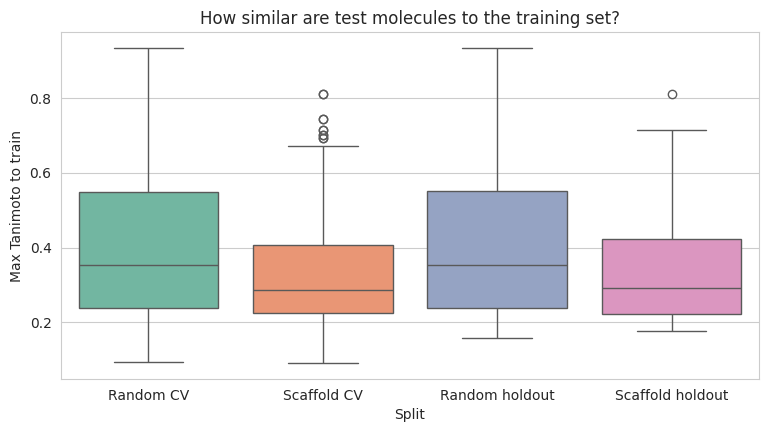

In [12]:
#@title 2.2 Nearest-neighbour similarity: random vs scaffold splits { display-mode: "form" }
import matplotlib.pyplot as plt, seaborn as sns
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in df.smiles_can]

def nn_sims(train_idx, test_idx):
    return [max(DataStructs.BulkTanimotoSimilarity(fps[i], [fps[j] for j in train_idx])) for i in test_idx]

res = {'Random CV': [], 'Scaffold CV': []}
for name, cv in [('Random CV', rand_cv), ('Scaffold CV', scaf_cv)]:
    for r in cv:
        if r['repeat'] == 0:   # one full pass over the data
            res[name] += nn_sims(r['train'], r['test'])

res['Random holdout'] = nn_sims(np.where(df.random_split == 'train')[0], np.where(df.random_split == 'test')[0])
res['Scaffold holdout'] = nn_sims(np.where(df.scaffold_split == 'train')[0], np.where(df.scaffold_split == 'test')[0])

summary = {k: {'mean': round(float(np.mean(v)), 3), 'median': round(float(np.median(v)), 3),
               'frac_below_0.4': round(float(np.mean(np.array(v) < 0.4)), 3)} for k, v in res.items()}
json.dump(summary, open(f'{ROOT}/results/s2_nn_similarity.json', 'w'), indent=2)
print(json.dumps(summary, indent=2))

plot_df = pd.DataFrame([(k, s) for k, v in res.items() for s in v], columns=['Split', 'Max Tanimoto to train'])
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=plot_df, x='Split', y='Max Tanimoto to train', palette='Set2', ax=ax)
ax.set_title('How similar are test molecules to the training set?')
save_fig(fig, 's2_nn_similarity'); plt.show()

In [13]:
#@title 2.3 Save + download Section 2 outputs { display-mode: "form" }
package_section('section2_splits', [
    f'{ROOT}/splits',
    f'{ROOT}/results/s2_nn_similarity.json',
    *glob.glob(f'{ROOT}/figures/s2_*.png'),
])

Packaged: /content/drive/MyDrive/AI IN DRUG DISCOVERY/MINI PROJECT/downloads/section2_splits.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
#@title 3.1 Features + model factory { display-mode: "form" }
import numpy as np, pandas as pd, json, warnings
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator, MACCSkeys, Descriptors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
RDLogger.DisableLog('rdApp.*'); warnings.filterwarnings('ignore')

# Reload from saved files (safe after a runtime restart)
df = pd.read_csv(f'{ROOT}/splits/holdout_splits.csv')
rand_cv = json.load(open(f'{ROOT}/splits/cv_random_5x5.json'))
scaf_cv = json.load(open(f'{ROOT}/splits/cv_scaffold_5x5.json'))
y = df.label.values
mols = [Chem.MolFromSmiles(s) for s in df.smiles_can]

mg = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
def feat_morgan(ms): return np.vstack([mg.GetCountFingerprintAsNumPy(m) for m in ms]).astype(np.float32)
def feat_maccs(ms):  return np.vstack([np.array(list(MACCSkeys.GenMACCSKeys(m)), dtype=np.float32) for m in ms])
def _safe(f, m):
    try: return f(m)
    except Exception: return 0.0
def feat_desc(ms):
    X = np.array([[_safe(f, m) for _, f in Descriptors.descList] for m in ms], dtype=np.float64)
    X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
    return (np.sign(X) * np.log1p(np.abs(X))).astype(np.float32)   # tame huge descriptor ranges

FEATS = {'Morgan': feat_morgan, 'MACCS': feat_maccs, 'RDKitDesc': feat_desc}
XS = {k: f(mols) for k, f in FEATS.items()}
print({k: v.shape for k, v in XS.items()})

MODELS = ['LogReg', 'SVM', 'RandomForest', 'XGBoost']

def make_model(name, feat, ytr, seed):
    scale = (feat != 'MACCS')
    pre = [StandardScaler()] if scale else []
    if name == 'LogReg':
        return make_pipeline(*pre, LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000))
    if name == 'SVM':
        return make_pipeline(*pre, SVC(C=1.0, kernel='rbf', gamma='scale', class_weight='balanced'))
    if name == 'RandomForest':
        return RandomForestClassifier(n_estimators=500, class_weight='balanced_subsample',
                                      n_jobs=1, random_state=seed)
    if name == 'XGBoost':
        spw = (ytr == 0).sum() / max((ytr == 1).sum(), 1)
        return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.5, scale_pos_weight=spw, eval_metric='logloss',
                             tree_method='hist', n_jobs=1, random_state=seed, verbosity=0)

def fit_score(name, feat, Xtr, ytr, Xte, seed):
    m = make_model(name, feat, ytr, seed).fit(Xtr, ytr)
    if name == 'SVM':
        return m.decision_function(Xte), 0.0, m      # threshold 0 on the margin
    return m.predict_proba(Xte)[:, 1], 0.5, m        # threshold 0.5 on probability
print('Ready.')

{'Morgan': (274, 2048), 'MACCS': (274, 167), 'RDKitDesc': (274, 217)}
Ready.


In [15]:
#@title 3.2 Cross-validation: random vs scaffold (5x5) { display-mode: "form" }
from joblib import Parallel, delayed
from sklearn.metrics import matthews_corrcoef, roc_auc_score, balanced_accuracy_score, average_precision_score
import pickle

def run_fold(split, r, feat, model):
    tr, te = np.array(r['train']), np.array(r['test'])
    s, thr, _ = fit_score(model, feat, XS[feat][tr], y[tr], XS[feat][te], SEED + r['repeat'])
    return split, feat, model, r['repeat'], te, s, thr

jobs = [(sp, r, f, m) for sp, cv in [('random', rand_cv), ('scaffold', scaf_cv)]
        for r in cv for f in FEATS for m in MODELS]
print('Fits to run:', len(jobs))
out = Parallel(n_jobs=-1, verbose=2)(delayed(run_fold)(*j) for j in jobs)

# Pool the 5 folds of each repeat, then compute metrics
pool = {}
for sp, f, m, rep, te, s, thr in out:
    d = pool.setdefault((sp, f, m, rep), {'idx': [], 's': [], 'thr': thr})
    d['idx'] += te.tolist(); d['s'] += s.tolist()

rows = []
for (sp, f, m, rep), d in pool.items():
    idx, s = np.array(d['idx']), np.array(d['s']); yt = y[idx]; yp = (s >= d['thr']).astype(int)
    rows.append(dict(split=sp, features=f, model=m, repeat=rep,
                     MCC=matthews_corrcoef(yt, yp), AUROC=roc_auc_score(yt, s),
                     AUPRC=average_precision_score(yt, s), BalAcc=balanced_accuracy_score(yt, yp)))
res = pd.DataFrame(rows)
res.to_csv(f'{ROOT}/results/s3_cv_metrics_per_repeat.csv', index=False)
pickle.dump(pool, open(f'{ROOT}/results/s3_oof_predictions.pkl', 'wb'))

summ = res.groupby(['split', 'features', 'model'])[['MCC', 'AUROC', 'AUPRC', 'BalAcc']].agg(['mean', 'std']).round(3)
summ.to_csv(f'{ROOT}/results/s3_cv_summary.csv')

for sp in ['scaffold', 'random']:
    t = res[res.split == sp].groupby(['features', 'model'])[['MCC', 'AUROC', 'BalAcc']].mean().round(3)
    print(f'\n=== {sp.upper()} CV (mean of 5 repeats), sorted by MCC ===')
    print(t.sort_values('MCC', ascending=False).to_string())

Fits to run: 600


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  37 tasks      | elapsed:   23.0s
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed:  1.2min
[Parallel(n_jobs=-1)]: Done 361 tasks      | elapsed:  2.5min
[Parallel(n_jobs=-1)]: Done 600 out of 600 | elapsed:  3.9min finished



=== SCAFFOLD CV (mean of 5 repeats), sorted by MCC ===
                          MCC  AUROC  BalAcc
features  model                             
MACCS     RandomForest  0.640  0.854   0.772
RDKitDesc SVM           0.624  0.882   0.790
Morgan    RandomForest  0.622  0.874   0.741
RDKitDesc RandomForest  0.605  0.855   0.739
Morgan    LogReg        0.571  0.841   0.742
          XGBoost       0.562  0.873   0.773
MACCS     SVM           0.555  0.849   0.771
          XGBoost       0.551  0.826   0.768
RDKitDesc XGBoost       0.544  0.833   0.761
MACCS     LogReg        0.521  0.837   0.772
RDKitDesc LogReg        0.513  0.852   0.768
Morgan    SVM           0.417  0.740   0.616

=== RANDOM CV (mean of 5 repeats), sorted by MCC ===
                          MCC  AUROC  BalAcc
features  model                             
MACCS     RandomForest  0.654  0.850   0.764
RDKitDesc SVM           0.636  0.887   0.788
Morgan    RandomForest  0.630  0.885   0.747
RDKitDesc RandomForest  0.624  0.86

Top 6 by scaffold-CV MCC (mean +/- std over 5 repeats):
  MACCS + RandomForest   scaffold 0.640 +/- 0.021 | random 0.654 +/- 0.021
  RDKitDesc + SVM        scaffold 0.624 +/- 0.031 | random 0.636 +/- 0.029
  Morgan + RandomForest  scaffold 0.622 +/- 0.015 | random 0.630 +/- 0.025
  RDKitDesc + RandomForest scaffold 0.605 +/- 0.032 | random 0.624 +/- 0.022
  Morgan + LogReg        scaffold 0.571 +/- 0.015 | random 0.564 +/- 0.011
  Morgan + XGBoost       scaffold 0.562 +/- 0.043 | random 0.571 +/- 0.048

Mean MCC gap (random - scaffold) across all 12 combos: 0.027


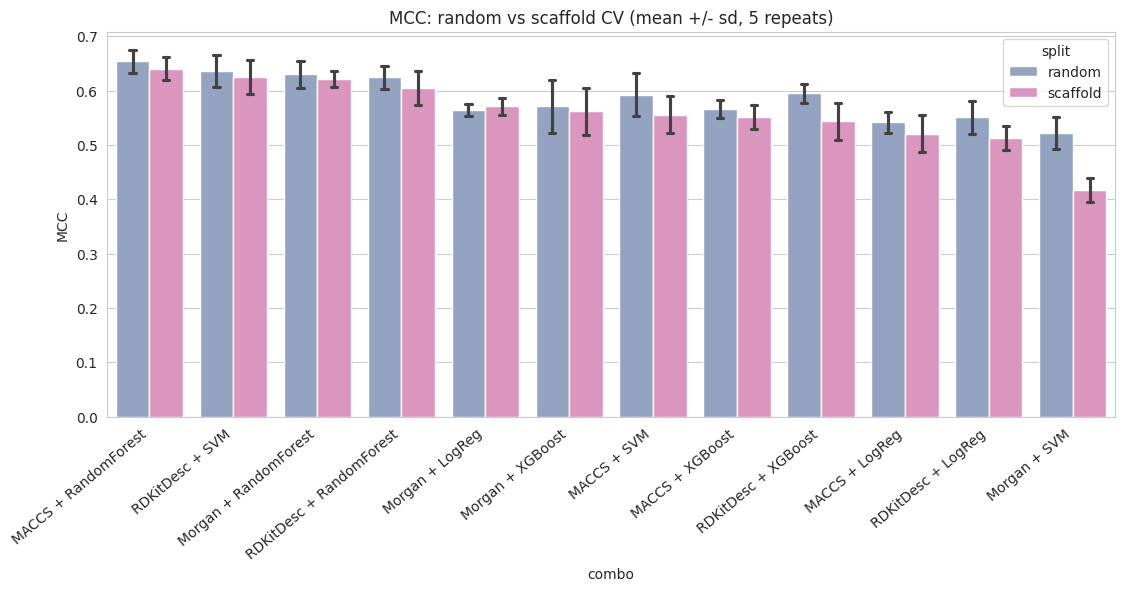

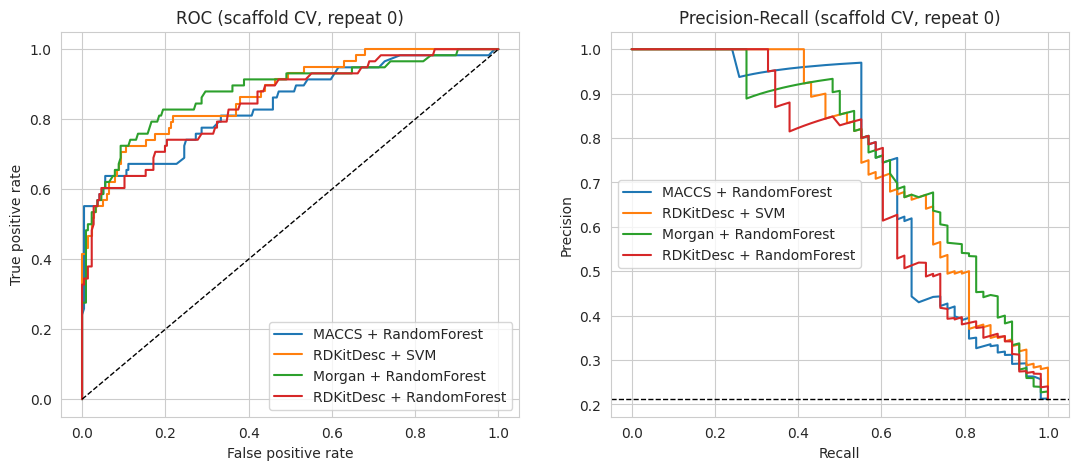

In [16]:
#@title 3.3 Variability across repeats + plots { display-mode: "form" }
import pickle, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_curve, precision_recall_curve

res = pd.read_csv(f'{ROOT}/results/s3_cv_metrics_per_repeat.csv')
pool = pickle.load(open(f'{ROOT}/results/s3_oof_predictions.pkl', 'rb'))
res['combo'] = res.features + ' + ' + res.model

order = res[res.split == 'scaffold'].groupby('combo').MCC.mean().sort_values(ascending=False).index.tolist()
tab = res.groupby(['split', 'combo']).MCC.agg(['mean', 'std']).round(3)
print('Top 6 by scaffold-CV MCC (mean +/- std over 5 repeats):')
for c in order[:6]:
    a, b = tab.loc[('scaffold', c)], tab.loc[('random', c)]
    print(f'  {c:22s} scaffold {a["mean"]:.3f} +/- {a["std"]:.3f} | random {b["mean"]:.3f} +/- {b["std"]:.3f}')
gap = (tab.loc['random']['mean'] - tab.loc['scaffold']['mean']).mean()
print(f'\nMean MCC gap (random - scaffold) across all 12 combos: {gap:.3f}')

# Bar chart
fig, ax = plt.subplots(figsize=(13, 5))
sns.barplot(data=res, x='combo', y='MCC', hue='split', order=order, errorbar='sd',
            palette={'random': '#8DA0CB', 'scaffold': '#E78AC3'}, ax=ax, capsize=0.15)
ax.set_xticklabels(order, rotation=40, ha='right'); ax.set_title('MCC: random vs scaffold CV (mean +/- sd, 5 repeats)')
save_fig(fig, 's3_mcc_random_vs_scaffold'); plt.show()

# ROC + PR for top 4 scaffold combos (repeat 0, pooled out-of-fold)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for c in order[:4]:
    f, m = c.split(' + ')
    d = pool[('scaffold', f, m, 0)]; idx, s = np.array(d['idx']), np.array(d['s']); yt = y[idx]
    fpr, tpr, _ = roc_curve(yt, s); ax[0].plot(fpr, tpr, label=c)
    p, r, _ = precision_recall_curve(yt, s); ax[1].plot(r, p, label=c)
ax[0].plot([0, 1], [0, 1], 'k--', lw=1); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate'); ax[0].set_title('ROC (scaffold CV, repeat 0)'); ax[0].legend()
ax[1].axhline(y.mean(), color='k', ls='--', lw=1); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('Precision-Recall (scaffold CV, repeat 0)'); ax[1].legend()
save_fig(fig, 's3_roc_pr_top4'); plt.show()

In [17]:
#@title 3.4 Fixed holdouts + bootstrap CI + save models { display-mode: "form" }
import joblib
from sklearn.metrics import matthews_corrcoef, roc_auc_score, balanced_accuracy_score, average_precision_score

def boot_ci(yt, s, thr, n=1000):
    rng = np.random.default_rng(SEED); v = []
    for _ in range(n):
        i = rng.integers(0, len(yt), len(yt))
        if yt[i].min() == yt[i].max(): continue
        v.append(matthews_corrcoef(yt[i], (s[i] >= thr).astype(int)))
    return np.percentile(v, [2.5, 97.5])

rows = []
for col, tag in [('scaffold_split', 'scaffold'), ('random_split', 'random')]:
    tr = np.where(df[col] == 'train')[0]; te = np.where(df[col] == 'test')[0]
    for f in FEATS:
        for m in MODELS:
            s, thr, mod = fit_score(m, f, XS[f][tr], y[tr], XS[f][te], SEED)
            yt, yp = y[te], (s >= thr).astype(int); lo, hi = boot_ci(yt, s, thr)
            rows.append(dict(split=tag, features=f, model=m, MCC=matthews_corrcoef(yt, yp), MCC_lo=lo, MCC_hi=hi,
                             AUROC=roc_auc_score(yt, s), AUPRC=average_precision_score(yt, s),
                             BalAcc=balanced_accuracy_score(yt, yp)))
            if tag == 'scaffold':
                joblib.dump(mod, f'{ROOT}/models/holdout_scaffold_{f}_{m}.joblib', compress=3)

ho = pd.DataFrame(rows).round(3)
ho.to_csv(f'{ROOT}/results/s3_holdout_metrics.csv', index=False)
for tag in ['scaffold', 'random']:
    print(f'\n=== {tag.upper()} HOLDOUT (test n=46), sorted by MCC ===')
    print(ho[ho.split == tag].sort_values('MCC', ascending=False).drop(columns='split').to_string(index=False))

# Final models on ALL curated data for the top 3 scaffold-CV combos
for c in order[:3]:
    f, m = c.split(' + ')
    _, _, mod = fit_score(m, f, XS[f], y, XS[f][:5], SEED)
    joblib.dump(mod, f'{ROOT}/models/final_{f}_{m}.joblib', compress=3)
print('\nSaved models:', sorted(os.listdir(f'{ROOT}/models')))


=== SCAFFOLD HOLDOUT (test n=46), sorted by MCC ===
 features        model   MCC  MCC_lo  MCC_hi  AUROC  AUPRC  BalAcc
   Morgan      XGBoost 0.795   0.577   0.955  0.951  0.931   0.897
   Morgan RandomForest 0.791   0.554   0.953  0.950  0.917   0.877
RDKitDesc          SVM 0.749   0.507   0.944  0.938  0.906   0.882
    MACCS          SVM 0.739   0.497   0.944  0.930  0.848   0.862
    MACCS      XGBoost 0.739   0.497   0.944  0.925  0.844   0.862
    MACCS RandomForest 0.739   0.497   0.944  0.923  0.841   0.862
    MACCS       LogReg 0.692   0.424   0.906  0.936  0.859   0.846
RDKitDesc      XGBoost 0.692   0.424   0.906  0.911  0.762   0.846
RDKitDesc       LogReg 0.649   0.361   0.864  0.877  0.827   0.830
   Morgan       LogReg 0.575   0.247   0.828  0.911  0.821   0.775
RDKitDesc RandomForest 0.377   0.073   0.660  0.924  0.832   0.647
   Morgan          SVM 0.091  -0.157   0.399  0.496  0.390   0.520

=== RANDOM HOLDOUT (test n=46), sorted by MCC ===
 features        model   

In [18]:
#@title 3.5 Save + download Section 3 outputs { display-mode: "form" }
package_section('section3_baselines', [
    f'{ROOT}/models',
    *glob.glob(f'{ROOT}/results/s3_*'),
    *glob.glob(f'{ROOT}/figures/s3_*.png'),
])

Packaged: /content/drive/MyDrive/AI IN DRUG DISCOVERY/MINI PROJECT/downloads/section3_baselines.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
#@title 4.1 GNN: featurization, model, training + smoke test { display-mode: "form" }
import torch, torch.nn as nn, torch.nn.functional as F, time
from rdkit import Chem
from sklearn.metrics import matthews_corrcoef, roc_auc_score, balanced_accuracy_score
torch.set_num_threads(2)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| torch', torch.__version__)

# ---------- featurization ----------
ATOMS = [6, 7, 8, 16, 15, 9, 17, 35, 53]
HYB = [Chem.HybridizationType.SP, Chem.HybridizationType.SP2, Chem.HybridizationType.SP3]
def onehot(v, ch):
    o = [0.0] * (len(ch) + 1); o[ch.index(v) if v in ch else len(ch)] = 1.0; return o
def atom_feat(a):
    return (onehot(a.GetAtomicNum(), ATOMS) + onehot(a.GetTotalDegree(), [1, 2, 3, 4]) +
            onehot(a.GetFormalCharge(), [-1, 0, 1]) + onehot(a.GetHybridization(), HYB) +
            onehot(a.GetTotalNumHs(), [0, 1, 2, 3]) + [float(a.GetIsAromatic()), float(a.IsInRing())])
def mol_graph(m):
    x = torch.tensor([atom_feat(a) for a in m.GetAtoms()], dtype=torch.float32)
    src, dst = [], []
    for b in m.GetBonds():
        i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx(); src += [i, j]; dst += [j, i]
    ei = torch.tensor([src, dst], dtype=torch.long) if src else torch.zeros((2, 0), dtype=torch.long)
    return x, ei
GRAPHS = [mol_graph(m) for m in mols]
N_FEAT = GRAPHS[0][0].shape[1]
print('atom feature size:', N_FEAT, '| graphs:', len(GRAPHS))

def collate(idx):
    xs, eis, bs, off = [], [], [], 0
    for k, i in enumerate(idx):
        x, ei = GRAPHS[i]
        xs.append(x); eis.append(ei + off); bs.append(torch.full((x.shape[0],), k, dtype=torch.long)); off += x.shape[0]
    return torch.cat(xs).to(device), torch.cat(eis, 1).to(device), torch.cat(bs).to(device), len(idx)

# ---------- model ----------
class GINLayer(nn.Module):
    def __init__(s, d, drop):
        super().__init__()
        s.eps = nn.Parameter(torch.zeros(1))
        s.mlp = nn.Sequential(nn.Linear(d, d), nn.BatchNorm1d(d), nn.ReLU(), nn.Linear(d, d))
        s.bn, s.drop = nn.BatchNorm1d(d), nn.Dropout(drop)
    def forward(s, h, ei):
        agg = torch.zeros_like(h).index_add_(0, ei[1], h[ei[0]])
        return s.drop(F.relu(s.bn(s.mlp((1 + s.eps) * h + agg)))) + h

class GNN(nn.Module):
    def __init__(s, din, d=64, L=3, drop=0.2):
        super().__init__()
        s.inp = nn.Linear(din, d)
        s.layers = nn.ModuleList([GINLayer(d, drop) for _ in range(L)])
        s.head = nn.Sequential(nn.Linear(2 * d, d), nn.ReLU(), nn.Dropout(drop), nn.Linear(d, 1))
    def forward(s, x, ei, batch, B):
        h = s.inp(x)
        for l in s.layers: h = l(h, ei)
        sm = torch.zeros(B, h.shape[1], device=h.device).index_add_(0, batch, h)
        cnt = torch.zeros(B, device=h.device).index_add_(0, batch, torch.ones(h.shape[0], device=h.device)).clamp(min=1).unsqueeze(1)
        return s.head(torch.cat([sm / cnt, sm], 1)).squeeze(1)

# ---------- training / prediction ----------
def train_gnn(tr_idx, seed, epochs=100, bs=32, lr=2e-3, wd=1e-3):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = GNN(N_FEAT).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    ytr = y[tr_idx]
    pw = torch.tensor((ytr == 0).sum() / max((ytr == 1).sum(), 1), dtype=torch.float32, device=device)
    for ep in range(epochs):
        model.train()
        perm = rng.permutation(tr_idx)
        for k in range(0, len(perm), bs):
            b = perm[k:k + bs]
            if len(b) < 2: continue
            x, ei, bt, B = collate(b)
            yt = torch.tensor(y[b], dtype=torch.float32, device=device)
            loss = F.binary_cross_entropy_with_logits(model(x, ei, bt, B), yt, pos_weight=pw)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
        sched.step()
    return model

@torch.no_grad()
def predict_gnn(model, idx):
    model.eval(); out = []
    for k in range(0, len(idx), 128):
        x, ei, bt, B = collate(idx[k:k + 128])
        out.append(torch.sigmoid(model(x, ei, bt, B)).cpu().numpy())
    return np.concatenate(out)

# ---------- smoke test: scaffold holdout, one model ----------
tr = np.where(df.scaffold_split == 'train')[0]; te = np.where(df.scaffold_split == 'test')[0]
t0 = time.time()
m = train_gnn(tr, SEED)
p = predict_gnn(m, te)
print(f'\nTrained 1 GNN in {time.time() - t0:.1f}s')
print(f'Scaffold holdout (1 model, 1 seed): MCC={matthews_corrcoef(y[te], (p >= 0.5).astype(int)):.3f} '
      f'AUROC={roc_auc_score(y[te], p):.3f} BalAcc={balanced_accuracy_score(y[te], (p >= 0.5).astype(int)):.3f}')

device: cuda | torch 2.11.0+cu130
atom feature size: 30 | graphs: 274

Trained 1 GNN in 13.8s
Scaffold holdout (1 model, 1 seed): MCC=0.749 AUROC=0.904 BalAcc=0.882


scaffold repeat 0 done | elapsed 1.0 min
scaffold repeat 1 done | elapsed 2.0 min
scaffold repeat 2 done | elapsed 2.9 min
scaffold repeat 3 done | elapsed 3.8 min
scaffold repeat 4 done | elapsed 4.7 min
random   repeat 0 done | elapsed 5.6 min
random   repeat 1 done | elapsed 6.5 min
random   repeat 2 done | elapsed 7.4 min
random   repeat 3 done | elapsed 8.3 min
random   repeat 4 done | elapsed 9.2 min

===== GNN vs classical (mean +/- sd over 5 repeats) =====

--- SCAFFOLD CV: top 4 overall ---
                            MCC         AUROC        BalAcc       
                           mean    std   mean    std   mean    std
combo                                                             
MACCS + RandomForest      0.640  0.021  0.854  0.008  0.772  0.008
RDKitDesc + SVM           0.624  0.031  0.882  0.007  0.790  0.013
Morgan + RandomForest     0.622  0.015  0.874  0.006  0.741  0.009
RDKitDesc + RandomForest  0.605  0.032  0.855  0.009  0.739  0.011
GNN rank by MCC: 12 of 13


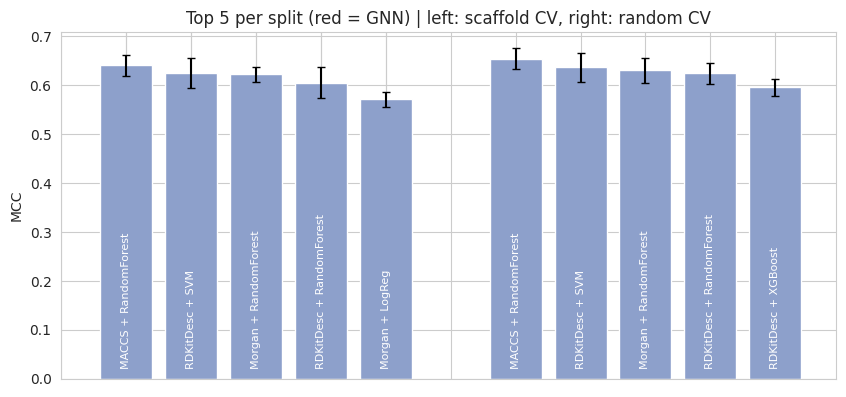

In [20]:
#@title 4.2 GNN CV on identical random + scaffold splits (resumable) { display-mode: "form" }
import pickle, os, time, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import matthews_corrcoef, roc_auc_score, balanced_accuracy_score, average_precision_score

N_SEEDS = 2
OOF_PATH = f'{ROOT}/results/s4_gnn_oof.pkl'
done = pickle.load(open(OOF_PATH, 'rb')) if os.path.exists(OOF_PATH) else {}
t0 = time.time()

for split, cv in [('scaffold', scaf_cv), ('random', rand_cv)]:
    for rep in range(5):
        if (split, rep) in done:
            continue
        idx_all, s_all = [], []
        for r in [r for r in cv if r['repeat'] == rep]:
            tr, te = np.array(r['train']), np.array(r['test'])
            ps = [predict_gnn(train_gnn(tr, SEED + rep * 100 + k), te) for k in range(N_SEEDS)]
            idx_all += te.tolist(); s_all += np.mean(ps, axis=0).tolist()
        done[(split, rep)] = {'idx': idx_all, 's': s_all}
        pickle.dump(done, open(OOF_PATH, 'wb'))
        print(f'{split:8s} repeat {rep} done | elapsed {(time.time() - t0) / 60:.1f} min')

rows = []
for (split, rep), d in done.items():
    idx, s = np.array(d['idx']), np.array(d['s']); yt = y[idx]; yp = (s >= 0.5).astype(int)
    rows.append(dict(split=split, features='Graph', model='GIN-ensemble', repeat=rep,
                     MCC=matthews_corrcoef(yt, yp), AUROC=roc_auc_score(yt, s),
                     AUPRC=average_precision_score(yt, s), BalAcc=balanced_accuracy_score(yt, yp)))
gres = pd.DataFrame(rows)
gres.to_csv(f'{ROOT}/results/s4_gnn_cv_metrics_per_repeat.csv', index=False)

cres = pd.read_csv(f'{ROOT}/results/s3_cv_metrics_per_repeat.csv')
cres['combo'] = cres.features + ' + ' + cres.model
gres['combo'] = 'GNN (GIN ensemble)'
allres = pd.concat([cres, gres], ignore_index=True)

print('\n===== GNN vs classical (mean +/- sd over 5 repeats) =====')
for sp in ['scaffold', 'random']:
    t = allres[allres.split == sp].groupby('combo')[['MCC', 'AUROC', 'BalAcc']].agg(['mean', 'std']).round(3)
    top = t.sort_values(('MCC', 'mean'), ascending=False).head(4)
    gnn = t.loc[['GNN (GIN ensemble)']]
    print(f'\n--- {sp.upper()} CV: top 4 overall ---'); print(top.to_string())
    print(f'GNN rank by MCC: {int((t[("MCC","mean")] > t.loc["GNN (GIN ensemble)", ("MCC","mean")]).sum()) + 1} of {len(t)}')

    # paired difference vs best classical (same repeats)
    best = cres[cres.split == sp].groupby('combo').MCC.mean().idxmax()
    a = gres[gres.split == sp].sort_values('repeat').MCC.values
    b = cres[(cres.split == sp) & (cres.combo == best)].sort_values('repeat').MCC.values
    print(f'GNN minus best classical ({best}): mean diff = {np.mean(a - b):+.3f} (per-repeat: {np.round(a - b, 3)})')

# plot
fig, ax = plt.subplots(figsize=(10, 4.5))
for k, sp in enumerate(['scaffold', 'random']):
    t = allres[allres.split == sp].groupby('combo').MCC.agg(['mean', 'std']).sort_values('mean', ascending=False).head(5)
    pos = np.arange(len(t)) + k * (len(t) + 1)
    cols = ['#C44E52' if 'GNN' in c else '#8DA0CB' for c in t.index]
    ax.bar(pos, t['mean'], yerr=t['std'], color=cols, capsize=3)
    ax.set_xticks(list(ax.get_xticks()) + list(pos))
ax.set_xticklabels([])
for k, sp in enumerate(['scaffold', 'random']):
    t = allres[allres.split == sp].groupby('combo').MCC.mean().sort_values(ascending=False).head(5)
    for i, c in enumerate(t.index):
        ax.text(i + k * 6, 0.02, c, rotation=90, va='bottom', ha='center', fontsize=8, color='white')
ax.set_ylabel('MCC'); ax.set_title('Top 5 per split (red = GNN) | left: scaffold CV, right: random CV')
save_fig(fig, 's4_gnn_vs_classical'); plt.show()

In [21]:
#@title 4.3 GNN full metrics, holdout + CI, save models { display-mode: "form" }
import torch, json
gres = pd.read_csv(f'{ROOT}/results/s4_gnn_cv_metrics_per_repeat.csv')
cres = pd.read_csv(f'{ROOT}/results/s3_cv_metrics_per_repeat.csv')

print('GNN CV metrics (mean +/- sd over 5 repeats):')
print(gres.groupby('split')[['MCC', 'AUROC', 'AUPRC', 'BalAcc']].agg(['mean', 'std']).round(3).to_string())
print('\nBest classical AUROC (mean over repeats) for reference:')
for sp in ['scaffold', 'random']:
    t = cres[cres.split == sp].groupby(['features', 'model']).AUROC.mean()
    print(f'  {sp:8s} {t.idxmax()}  AUROC = {t.max():.3f}')

def boot_ci(yt, s, thr=0.5, n=1000):
    rng = np.random.default_rng(SEED); v = []
    for _ in range(n):
        i = rng.integers(0, len(yt), len(yt))
        if yt[i].min() == yt[i].max(): continue
        v.append(matthews_corrcoef(yt[i], (s[i] >= thr).astype(int)))
    return np.percentile(v, [2.5, 97.5])

rows = []
for col, tag in [('scaffold_split', 'scaffold'), ('random_split', 'random')]:
    tr = np.where(df[col] == 'train')[0]; te = np.where(df[col] == 'test')[0]
    models = [train_gnn(tr, SEED + k) for k in range(2)]
    p = np.mean([predict_gnn(m, te) for m in models], axis=0)
    yt, yp = y[te], (p >= 0.5).astype(int); lo, hi = boot_ci(yt, p)
    rows.append(dict(split=tag, MCC=matthews_corrcoef(yt, yp), MCC_lo=lo, MCC_hi=hi,
                     AUROC=roc_auc_score(yt, p), AUPRC=average_precision_score(yt, p),
                     BalAcc=balanced_accuracy_score(yt, yp)))
    if tag == 'scaffold':
        for k, m in enumerate(models):
            torch.save(m.state_dict(), f'{ROOT}/models/holdout_scaffold_GNN_seed{k}.pt')
ho = pd.DataFrame(rows).round(3)
ho.to_csv(f'{ROOT}/results/s4_gnn_holdout_metrics.csv', index=False)
print('\nGNN fixed-holdout results (2-seed ensemble, test n=46):'); print(ho.to_string(index=False))

# Final ensemble: 5 seeds trained on ALL curated data
all_idx = np.arange(len(y))
for k in range(5):
    torch.save(train_gnn(all_idx, SEED + k).state_dict(), f'{ROOT}/models/final_GNN_seed{k}.pt')
json.dump({'arch': 'GIN-residual, 3 layers, hidden 64, dropout 0.2, mean+sum readout',
           'atom_features': int(N_FEAT), 'epochs': 100, 'batch_size': 32, 'lr': 0.002,
           'weight_decay': 0.001, 'loss': 'BCE with pos_weight', 'threshold': 0.5},
          open(f'{ROOT}/models/GNN_config.json', 'w'), indent=2)
print('\nSaved GNN files:', sorted(f for f in os.listdir(f'{ROOT}/models') if 'GNN' in f))

GNN CV metrics (mean +/- sd over 5 repeats):
            MCC         AUROC         AUPRC        BalAcc       
           mean    std   mean    std   mean    std   mean    std
split                                                           
random    0.512  0.069  0.835  0.014  0.686  0.007  0.748  0.025
scaffold  0.503  0.022  0.828  0.014  0.685  0.019  0.751  0.011

Best classical AUROC (mean over repeats) for reference:
  scaffold ('RDKitDesc', 'SVM')  AUROC = 0.882
  random   ('RDKitDesc', 'SVM')  AUROC = 0.887

GNN fixed-holdout results (2-seed ensemble, test n=46):
   split   MCC  MCC_lo  MCC_hi  AUROC  AUPRC  BalAcc
scaffold 0.749   0.507   0.944  0.893  0.782   0.882
  random 0.586   0.266   0.856  0.872  0.717   0.700

Saved GNN files: ['GNN_config.json', 'final_GNN_seed0.pt', 'final_GNN_seed1.pt', 'final_GNN_seed2.pt', 'final_GNN_seed3.pt', 'final_GNN_seed4.pt', 'holdout_scaffold_GNN_seed0.pt', 'holdout_scaffold_GNN_seed1.pt']


In [22]:
#@title 4.4 Save + download Section 4 outputs { display-mode: "form" }
package_section('section4_gnn', [
    *glob.glob(f'{ROOT}/models/*GNN*'),
    *glob.glob(f'{ROOT}/results/s4_*'),
    *glob.glob(f'{ROOT}/figures/s4_*.png'),
])

Packaged: /content/drive/MyDrive/AI IN DRUG DISCOVERY/MINI PROJECT/downloads/section4_gnn.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Fits: 225

Label-shuffle test (scaffold CV):
  MACCS + RandomForest   real MCC = 0.640 | shuffled MCC mean = -0.019, sd = 0.051, max = +0.069  (n=15)
  RDKitDesc + SVM        real MCC = 0.624 | shuffled MCC mean = -0.062, sd = 0.040, max = +0.001  (n=15)
  Morgan + RandomForest  real MCC = 0.622 | shuffled MCC mean = -0.027, sd = 0.048, max = +0.117  (n=15)


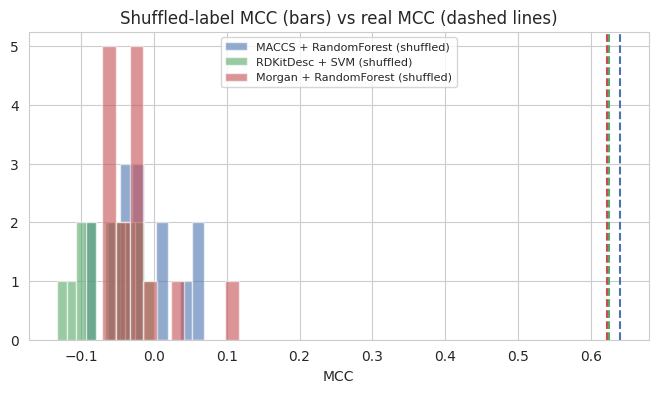

In [23]:
#@title 5.1 Label-shuffling sanity test { display-mode: "form" }
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
from sklearn.metrics import matthews_corrcoef

combos = [('MACCS', 'RandomForest'), ('RDKitDesc', 'SVM'), ('Morgan', 'RandomForest')]
N_PERM = 3
yperm = {p: np.random.default_rng(1000 + p).permutation(y) for p in range(N_PERM)}

def shuffled_fold(f, m, r, p):
    tr, te = np.array(r['train']), np.array(r['test'])
    s, thr, _ = fit_score(m, f, XS[f][tr], yperm[p][tr], XS[f][te], SEED)
    return f, m, r['repeat'], p, te, s, thr

jobs = [(f, m, r, p) for (f, m) in combos for r in scaf_cv for p in range(N_PERM)]
print('Fits:', len(jobs))
out = Parallel(n_jobs=-1, verbose=0)(delayed(shuffled_fold)(*j) for j in jobs)

pool = {}
for f, m, rep, p, te, s, thr in out:
    d = pool.setdefault((f, m, rep, p), {'idx': [], 's': [], 'thr': thr})
    d['idx'] += te.tolist(); d['s'] += s.tolist()

rows = []
for (f, m, rep, p), d in pool.items():
    idx, s = np.array(d['idx']), np.array(d['s'])
    rows.append(dict(combo=f'{f} + {m}', repeat=rep, perm=p,
                     MCC_shuffled=matthews_corrcoef(yperm[p][idx], (s >= d['thr']).astype(int))))
sh = pd.DataFrame(rows)
sh.to_csv(f'{ROOT}/results/s5_label_shuffle.csv', index=False)

real = pd.read_csv(f'{ROOT}/results/s3_cv_metrics_per_repeat.csv')
real = real[real.split == 'scaffold'].assign(combo=lambda d: d.features + ' + ' + d.model).groupby('combo').MCC.mean()

print('\nLabel-shuffle test (scaffold CV):')
for c in sh.combo.unique():
    v = sh[sh.combo == c].MCC_shuffled
    print(f'  {c:22s} real MCC = {real[c]:.3f} | shuffled MCC mean = {v.mean():+.3f}, sd = {v.std():.3f}, max = {v.max():+.3f}  (n={len(v)})')

fig, ax = plt.subplots(figsize=(8, 4))
for c, col in zip(sh.combo.unique(), ['#4C72B0', '#55A868', '#C44E52']):
    ax.hist(sh[sh.combo == c].MCC_shuffled, bins=10, alpha=0.6, color=col, label=f'{c} (shuffled)')
    ax.axvline(real[c], color=col, ls='--')
ax.set_xlabel('MCC'); ax.set_title('Shuffled-label MCC (bars) vs real MCC (dashed lines)'); ax.legend(fontsize=8)
save_fig(fig, 's5_label_shuffle'); plt.show()

In [24]:
#@title 5.2 Nested threshold calibration { display-mode: "form" }
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import balanced_accuracy_score

groups = df['group'].values
top4 = [('MACCS', 'RandomForest'), ('RDKitDesc', 'SVM'), ('Morgan', 'RandomForest'), ('RDKitDesc', 'RandomForest')]
REPS = [0, 1, 2]

def nested_fold(f, m, r):
    tr, te = np.array(r['train']), np.array(r['test'])
    oof = np.zeros(len(tr))
    for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(tr, y[tr], groups[tr]):
        s_, _, _ = fit_score(m, f, XS[f][tr[a]], y[tr[a]], XS[f][tr[b]], SEED)
        oof[b] = s_
    cand = np.unique(np.quantile(oof, np.linspace(0.4, 0.97, 60)))
    mccs = np.array([matthews_corrcoef(y[tr], (oof >= t).astype(int)) for t in cand])
    thr_star = float(np.median(cand[np.isclose(mccs, mccs.max())]))
    s, thr0, _ = fit_score(m, f, XS[f][tr], y[tr], XS[f][te], SEED)
    return f, m, r['repeat'], te, s, thr0, thr_star

jobs = [(f, m, r) for (f, m) in top4 for r in scaf_cv if r['repeat'] in REPS]
print('Fits (approx):', len(jobs) * 6)
out = Parallel(n_jobs=-1, verbose=0)(delayed(nested_fold)(*j) for j in jobs)

pool = {}
for f, m, rep, te, s, thr0, thr_star in out:
    d = pool.setdefault((f, m, rep), {'idx': [], 's': [], 'thr0': thr0, 'thrs': []})
    d['idx'] += te.tolist(); d['s'] += s.tolist(); d['thrs'].append(thr_star)

rows = []
for (f, m, rep), d in pool.items():
    idx, s = np.array(d['idx']), np.array(d['s']); yt = y[idx]
    # each outer fold uses ITS OWN tuned threshold; rebuild per-fold predictions
    rows.append((f, m, rep, idx, s, d['thr0'], d['thrs']))

res = []
nfold = {}
for f, m, rep, te, s, thr0, thr_star in out:
    nfold.setdefault((f, m, rep), []).append((te, s, thr0, thr_star))
for (f, m, rep), parts in nfold.items():
    idx = np.concatenate([p[0] for p in parts]); yt = y[idx]
    yp0 = np.concatenate([(p[1] >= p[2]).astype(int) for p in parts])
    yp1 = np.concatenate([(p[1] >= p[3]).astype(int) for p in parts])
    res.append(dict(combo=f'{f} + {m}', repeat=rep,
                    MCC_default=matthews_corrcoef(yt, yp0), MCC_tuned=matthews_corrcoef(yt, yp1),
                    BalAcc_default=balanced_accuracy_score(yt, yp0), BalAcc_tuned=balanced_accuracy_score(yt, yp1)))
cal = pd.DataFrame(res); cal.to_csv(f'{ROOT}/results/s5_threshold_calibration.csv', index=False)
print('\nScaffold CV, mean over 3 repeats (default cutoff vs nested-tuned cutoff):')
print(cal.groupby('combo')[['MCC_default', 'MCC_tuned', 'BalAcc_default', 'BalAcc_tuned']].mean().round(3).to_string())

Fits (approx): 360

Scaffold CV, mean over 3 repeats (default cutoff vs nested-tuned cutoff):
                          MCC_default  MCC_tuned  BalAcc_default  BalAcc_tuned
combo                                                                         
MACCS + RandomForest            0.641      0.633           0.770         0.764
Morgan + RandomForest           0.628      0.607           0.742         0.769
RDKitDesc + RandomForest        0.591      0.581           0.732         0.747
RDKitDesc + SVM                 0.626      0.597           0.789         0.764


In [25]:
#@title 5.3 Save + download Section 5 outputs { display-mode: "form" }
package_section('section5_sanity', [
    *glob.glob(f'{ROOT}/results/s5_*'),
    *glob.glob(f'{ROOT}/figures/s5_*.png'),
])

Packaged: /content/drive/MyDrive/AI IN DRUG DISCOVERY/MINI PROJECT/downloads/section5_sanity.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
#@title 5.3 GNN: best-possible-threshold upper bound { display-mode: "form" }
import pickle
from sklearn.metrics import matthews_corrcoef
done = pickle.load(open(f'{ROOT}/results/s4_gnn_oof.pkl', 'rb'))
ths = np.linspace(0.05, 0.95, 91)
rows = []
for sp in ['scaffold', 'random']:
    for rep in range(5):
        d = done[(sp, rep)]; idx = np.array(d['idx']); s = np.array(d['s']); yt = y[idx]
        m = [matthews_corrcoef(yt, (s >= t).astype(int)) for t in ths]
        rows.append(dict(split=sp, repeat=rep, MCC_at_0p5=matthews_corrcoef(yt, (s >= 0.5).astype(int)),
                         MCC_best_possible=max(m), best_threshold=ths[int(np.argmax(m))]))
r = pd.DataFrame(rows); r.to_csv(f'{ROOT}/results/s5_gnn_threshold_upper_bound.csv', index=False)
print(r.groupby('split')[['MCC_at_0p5', 'MCC_best_possible', 'best_threshold']].mean().round(3).to_string())
print('\nBest classical for reference: scaffold 0.640 | random 0.654')

          MCC_at_0p5  MCC_best_possible  best_threshold
split                                                  
random         0.512              0.592           0.828
scaffold       0.503              0.563           0.930

Best classical for reference: scaffold 0.640 | random 0.654


In [27]:
#@title 5.4 Save + download Section 5 outputs { display-mode: "form" }
package_section('section5_sanity', [
    *glob.glob(f'{ROOT}/results/s5_*'),
    *glob.glob(f'{ROOT}/figures/s5_*.png'),
])

Packaged: /content/drive/MyDrive/AI IN DRUG DISCOVERY/MINI PROJECT/downloads/section5_sanity.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Baseline carcinogen rate = 0.212

                    alert  n  carcinogens  carc_rate  enrichment  p_one_sided
Benzylic / allylic halide  1            1      1.000        4.72       0.2117
Alkyl sulfonate / sulfate  1            1      1.000        4.72       0.2117
                Hydrazine  8            8      1.000        4.72       0.0000
           Azo (aromatic) 15           14      0.933        4.41       0.0000
             Alkyl halide  5            4      0.800        3.78       0.0078
                N-nitroso  2            1      0.500        2.36       0.3792
           Aromatic amine 32           12      0.375        1.77       0.0185
           Aromatic nitro  4            1      0.250        1.18       0.6161
                 Aldehyde  4            1      0.250        1.18       0.6161
         Michael acceptor 35            3      0.086        0.40       0.9909
      Epoxide / aziridine  4            0      0.000        0.00       1.0000
     PAH (3+ fused rings)  1  

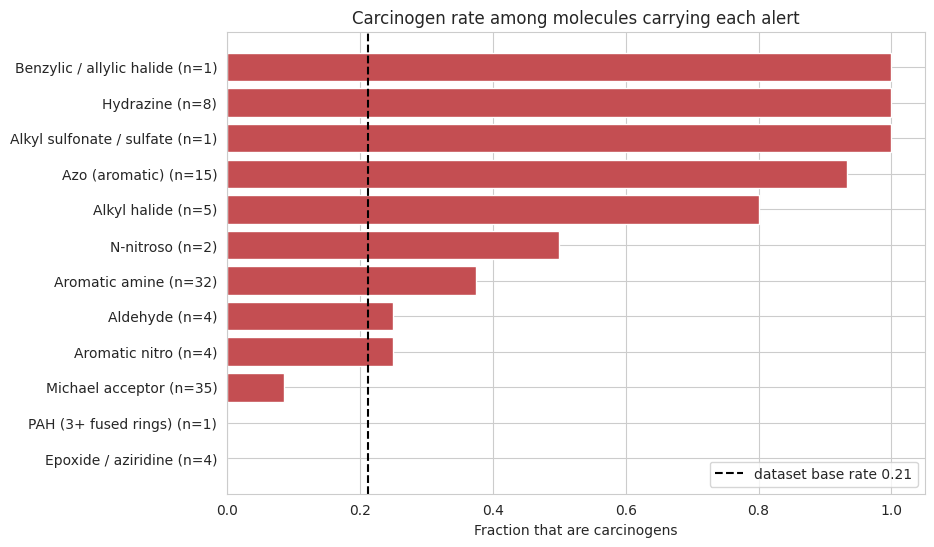

In [28]:
#@title 6.1 Structural alerts: enrichment + alert-only baseline { display-mode: "form" }
import pandas as pd, numpy as np, json, matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from scipy.stats import fisher_exact
from sklearn.metrics import matthews_corrcoef, roc_auc_score, balanced_accuracy_score
RDLogger.DisableLog('rdApp.*')

df = pd.read_csv(f'{ROOT}/splits/holdout_splits.csv')
y = df.label.values
mols = [Chem.MolFromSmiles(s) for s in df.smiles_can]

# Defined a priori (not tuned on this dataset)
ALERTS = {
    'Aromatic amine':            ['c[NX3;H2,H1;!$(N-C=O);!$(N-S=O)]'],
    'Aromatic nitro':            ['c[N+](=O)[O-]'],
    'Aromatic nitroso / N-OH':   ['c[NX2]=O', 'c[NX3][OX2H]'],
    'N-nitroso':                 ['[#7]-[NX2]=O'],
    'Azo (aromatic)':            ['cN=Nc'],
    'Triazene / diazo / azide':  ['[#7]=[#7]-[#7]', '[N+]#N', 'N=[N+]=[N-]'],
    'Hydrazine':                 ['[NX3;!$(N-C=O)][NX3;!$(N-C=O)]'],
    'Epoxide / aziridine':       ['C1OC1', 'C1[NX3]C1'],
    'Alkyl halide':              ['[CX4][Cl,Br,I]'],
    'Benzylic / allylic halide': ['[CX4;$(C-c),$(C-C=C)][Cl,Br,I]'],
    'N- or S-mustard':           ['[NX3,SX2][CH2][CH2][Cl,Br,I]'],
    'Halo-alkene':               ['[CX3]=[CX3][Cl,Br,I]'],
    'Alkyl sulfonate / sulfate': ['[CX4]O[SX4](=O)(=O)'],
    'Michael acceptor':          ['[CX3;!a]=[CX3;!a]-[CX3]=O'],
    'Aldehyde':                  ['[CX3H1](=O)[#6]'],
    'beta-Lactone':              ['O=C1CCO1'],
    'PAH (3+ fused rings)':      ['c1ccc2c(c1)ccc1ccccc12', 'c1ccc2cc3ccccc3cc2c1'],
}
PATS = {k: [Chem.MolFromSmarts(s) for s in v] for k, v in ALERTS.items()}
assert all(p is not None for v in PATS.values() for p in v), 'bad SMARTS'

names = list(ALERTS)
H = np.array([[int(any(m.HasSubstructMatch(p) for p in PATS[a])) for a in names] for m in mols])
pd.DataFrame(H, columns=names).assign(smiles=df.smiles_can, label=y).to_csv(f'{ROOT}/results/s6_alert_matrix.csv', index=False)

base = y.mean(); rows = []
for j, a in enumerate(names):
    n = int(H[:, j].sum()); c = int(y[H[:, j] == 1].sum())
    if n == 0: continue
    tab = [[c, n - c], [y.sum() - c, (len(y) - y.sum()) - (n - c)]]
    p = fisher_exact(tab, alternative='greater')[1]
    rows.append(dict(alert=a, n=n, carcinogens=c, carc_rate=round(c / n, 3), enrichment=round(c / n / base, 2), p_one_sided=round(p, 4)))
et = pd.DataFrame(rows).sort_values('enrichment', ascending=False)
et.to_csv(f'{ROOT}/results/s6_alert_enrichment.csv', index=False)
print(f'Baseline carcinogen rate = {base:.3f}\n'); print(et.to_string(index=False))
print('\nAlerts with 0 matches in this dataset:', [a for j, a in enumerate(names) if H[:, j].sum() == 0])

# Alert-only rule baseline
n_alerts = H.sum(1); rule = (n_alerts > 0).astype(int)
tp = ((rule == 1) & (y == 1)).sum(); fn = ((rule == 0) & (y == 1)).sum()
tn = ((rule == 0) & (y == 0)).sum(); fp = ((rule == 1) & (y == 0)).sum()
rb = dict(MCC=round(matthews_corrcoef(y, rule), 3), AUROC=round(roc_auc_score(y, n_alerts), 3),
          BalAcc=round(balanced_accuracy_score(y, rule), 3), sensitivity=round(tp / (tp + fn), 3),
          specificity=round(tn / (tn + fp), 3), frac_molecules_with_alert=round(rule.mean(), 3))
json.dump(rb, open(f'{ROOT}/results/s6_alert_rule_baseline.json', 'w'), indent=2)
print('\nAlert-only rule ("any alert => carcinogen") on all 274 molecules:', rb)
print('(No training involved, so this is comparable with the CV numbers.)')

fig, ax = plt.subplots(figsize=(9, 6))
d = et.sort_values('carc_rate')
ax.barh(d.alert + ' (n=' + d.n.astype(str) + ')', d.carc_rate, color='#C44E52')
ax.axvline(base, color='k', ls='--', label=f'dataset base rate {base:.2f}')
ax.set_xlabel('Fraction that are carcinogens'); ax.set_title('Carcinogen rate among molecules carrying each alert'); ax.legend()
save_fig(fig, 's6_alert_enrichment'); plt.show()

Out-of-fold MACCS+RF (scaffold CV) vs structural alerts
           n  pct_with_alert
outcome                     
FN        26            53.8
FP         4            75.0
TN       212            27.4
TP        32            71.9

Top 20 predicted carcinogens: 19/20 are true carcinogens; 20/20 carry at least one alert
                                       smiles  label  score                         alerts
O=S(=O)(O)c1cc(S(=O)(=O)O)c2c(N=Nc3ccccc3)...      1  1.000                 Azo (aromatic)
O=S(=O)(O)c1ccc(N=Nc2c(O)ccc3cc(S(=O)(=O)O...      1  1.000                 Azo (aromatic)
O=S(=O)(O)c1cc(S(=O)(=O)O)c2c(N=Nc3ccc(S(=...      1  1.000                 Azo (aromatic)
O=S(=O)(O)c1c(N=Nc2c(O)ccc3ccccc23)ccc2ccc...      1  1.000                 Azo (aromatic)
O=S(=O)(O)c1ccc2c(N=Nc3ccc(S(=O)(=O)O)c4cc...      1  0.988                 Azo (aromatic)
Cc1cc(C)c(N=Nc2cc(S(=O)(=O)O)c3ccccc3c2O)c...      1  0.986                 Azo (aromatic)
Nc1cc(S(=O)(=O)O)cc2cc(S(=O)(=O)O)c(N=Nc3c.

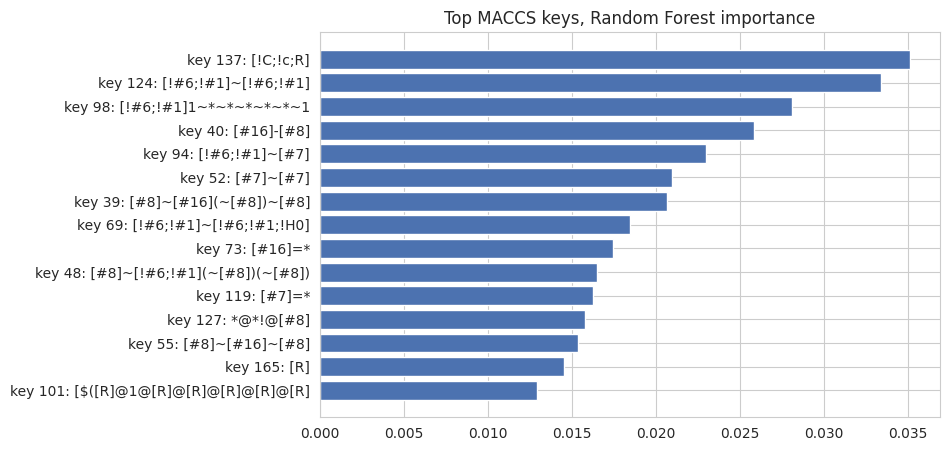

In [29]:
#@title 6.2 Cross-check model vs alerts + feature importance { display-mode: "form" }
import pickle, joblib
from rdkit.Chem import MACCSkeys

pool = pickle.load(open(f'{ROOT}/results/s3_oof_predictions.pkl', 'rb'))
score = np.zeros(len(y)); cnt = np.zeros(len(y))
for rep in range(5):                                   # MACCS+RF, scaffold CV, averaged over repeats
    d = pool[('scaffold', 'MACCS', 'RandomForest', rep)]
    idx = np.array(d['idx']); score[idx] += np.array(d['s']); cnt[idx] += 1
score /= cnt; pred = (score >= 0.5).astype(int)
has = H.sum(1) > 0
alert_list = [', '.join(a for j, a in enumerate(names) if H[i, j]) or '-' for i in range(len(y))]
T = pd.DataFrame(dict(smiles=df.smiles_can, label=y, score=score.round(3), pred=pred, has_alert=has, alerts=alert_list))
T['outcome'] = np.select([(y == 1) & (pred == 1), (y == 0) & (pred == 1), (y == 1) & (pred == 0)], ['TP', 'FP', 'FN'], 'TN')
T.to_csv(f'{ROOT}/results/s6_predictions_vs_alerts.csv', index=False)

print('Out-of-fold MACCS+RF (scaffold CV) vs structural alerts')
print(T.groupby('outcome').agg(n=('label', 'size'), pct_with_alert=('has_alert', lambda v: round(100 * v.mean(), 1))).to_string())

top = T.sort_values('score', ascending=False).head(20)
print(f'\nTop 20 predicted carcinogens: {int(top.label.sum())}/20 are true carcinogens; '
      f'{int(top.has_alert.sum())}/20 carry at least one alert')
print(top[['smiles', 'label', 'score', 'alerts']].to_string(index=False, max_colwidth=45))

fn = T[T.outcome == 'FN'].sort_values('score')
print(f'\nMissed carcinogens (false negatives): {len(fn)} | with an alert: {int(fn.has_alert.sum())}')
print(fn[['smiles', 'score', 'alerts']].head(15).to_string(index=False, max_colwidth=45))
fp = T[T.outcome == 'FP'].sort_values('score', ascending=False)
print(f'\nFalse positives: {len(fp)} | with an alert: {int(fp.has_alert.sum())}')
print(fp[['smiles', 'score', 'alerts']].head(10).to_string(index=False, max_colwidth=45))

# Which MACCS keys does the final RF rely on?
rf = joblib.load(f'{ROOT}/models/final_MACCS_RandomForest.joblib')
imp = rf.feature_importances_; top_k = np.argsort(imp)[::-1][:15]
print('\nTop 15 MACCS keys by RF importance (impurity-based; interpret with care):')
for k in top_k:
    sm = MACCSkeys.smartsPatts.get(int(k), ('?', 0))[0]
    print(f'  key {int(k):3d}  importance {imp[k]:.3f}  SMARTS: {sm}')
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([f'key {int(k)}: {MACCSkeys.smartsPatts.get(int(k), ("?",0))[0][:28]}' for k in top_k[::-1]], imp[top_k[::-1]], color='#4C72B0')
ax.set_title('Top MACCS keys, Random Forest importance'); save_fig(fig, 's6_maccs_importance'); plt.show()

In [30]:
#@title 6.3 Save + download Section 6 outputs { display-mode: "form" }
package_section('section6_alerts', [
    *glob.glob(f'{ROOT}/results/s6_*'),
    *glob.glob(f'{ROOT}/figures/s6_*.png'),
])

Packaged: /content/drive/MyDrive/AI IN DRUG DISCOVERY/MINI PROJECT/downloads/section6_alerts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
#@title 7.1 Robustness: ablate analog series + cluster-based CV { display-mode: "form" }
import pickle, json, numpy as np, pandas as pd
from joblib import Parallel, delayed
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator
from rdkit.ML.Cluster import Butina
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import matthews_corrcoef, roc_auc_score

TOP = [('MACCS', 'RandomForest'), ('RDKitDesc', 'SVM'), ('Morgan', 'RandomForest')]

# ---------- (a) remove azo + hydrazine molecules from existing out-of-fold predictions ----------
A = pd.read_csv(f'{ROOT}/results/s6_alert_matrix.csv')
series = ((A['Azo (aromatic)'] == 1) | (A['Hydrazine'] == 1)).values
print(f'Series removed: {series.sum()} molecules ({int(y[series].sum())} carcinogens)')
print(f'Remaining: {(~series).sum()} molecules ({int(y[~series].sum())} carcinogens)\n')

pool = pickle.load(open(f'{ROOT}/results/s3_oof_predictions.pkl', 'rb'))
rows = []
for f, m in TOP:
    for rep in range(5):
        d = pool[('scaffold', f, m, rep)]
        idx, s = np.array(d['idx']), np.array(d['s']); keep = ~series[idx]
        yt, yp = y[idx][keep], (s[keep] >= d['thr']).astype(int)
        rows.append(dict(combo=f'{f} + {m}', repeat=rep,
                         MCC_all=matthews_corrcoef(y[idx], (s >= d['thr']).astype(int)),
                         MCC_no_series=matthews_corrcoef(yt, yp),
                         AUROC_all=roc_auc_score(y[idx], s), AUROC_no_series=roc_auc_score(yt, s[keep])))
abl = pd.DataFrame(rows); abl.to_csv(f'{ROOT}/results/s7_series_ablation.csv', index=False)
print('Scaffold CV, with vs without azo/hydrazine series (mean over 5 repeats):')
print(abl.groupby('combo')[['MCC_all', 'MCC_no_series', 'AUROC_all', 'AUROC_no_series']].mean().round(3).to_string())

# ---------- (b) cluster-grouped CV ----------
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [gen.GetFingerprint(m) for m in mols]
dists = []
for i in range(1, len(fps)):
    dists.extend([1 - x for x in DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i])])
clusters = Butina.ClusterData(dists, len(fps), 0.6, isDistData=True)   # similarity >= 0.4 => same cluster
cid = np.zeros(len(fps), dtype=int)
for k, c in enumerate(clusters):
    for i in c: cid[i] = k
sizes = np.array([len(c) for c in clusters])
print(f'\nClusters: {len(clusters)} | singletons: {(sizes == 1).sum()} | largest cluster: {sizes.max()}')

idx_all = np.arange(len(y)); cv = []
for rep in range(5):
    for fold, (tr, te) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED + rep).split(idx_all, y, cid)):
        cv.append({'repeat': rep, 'fold': fold, 'train': tr.tolist(), 'test': te.tolist()})
json.dump(cv, open(f'{ROOT}/splits/cv_cluster_5x5.json', 'w'))
for r in cv:   # leakage audit: no cluster shared between train and test
    assert not set(cid[r['train']]) & set(cid[r['test']])
print('Cluster-CV audit PASSED')

def run_fold(f, m, r):
    tr, te = np.array(r['train']), np.array(r['test'])
    s, thr, _ = fit_score(m, f, XS[f][tr], y[tr], XS[f][te], SEED + r['repeat'])
    return f, m, r['repeat'], te, s, thr
out = Parallel(n_jobs=-1)(delayed(run_fold)(f, m, r) for (f, m) in TOP for r in cv)

P = {}
for f, m, rep, te, s, thr in out:
    d = P.setdefault((f, m, rep), {'idx': [], 's': [], 'thr': thr}); d['idx'] += te.tolist(); d['s'] += s.tolist()
rows = []
for (f, m, rep), d in P.items():
    idx, s = np.array(d['idx']), np.array(d['s'])
    rows.append(dict(combo=f'{f} + {m}', repeat=rep, MCC=matthews_corrcoef(y[idx], (s >= d['thr']).astype(int)),
                     AUROC=roc_auc_score(y[idx], s)))
cl = pd.DataFrame(rows); cl.to_csv(f'{ROOT}/results/s7_cluster_cv.csv', index=False)

sc = pd.read_csv(f'{ROOT}/results/s3_cv_metrics_per_repeat.csv')
sc = sc[sc.split == 'scaffold'].assign(combo=lambda d: d.features + ' + ' + d.model).groupby('combo')[['MCC', 'AUROC']].mean()
cm = cl.groupby('combo')[['MCC', 'AUROC']].agg(['mean', 'std'])
print('\nScaffold CV vs cluster CV (mean over 5 repeats):')
for c in cm.index:
    print(f'  {c:22s} scaffold MCC {sc.loc[c, "MCC"]:.3f} | cluster MCC {cm.loc[c, ("MCC", "mean")]:.3f} +/- {cm.loc[c, ("MCC", "std")]:.3f}'
          f' | cluster AUROC {cm.loc[c, ("AUROC", "mean")]:.3f}')

Series removed: 23 molecules (22 carcinogens)
Remaining: 251 molecules (36 carcinogens)

Scaffold CV, with vs without azo/hydrazine series (mean over 5 repeats):
                       MCC_all  MCC_no_series  AUROC_all  AUROC_no_series
combo                                                                    
MACCS + RandomForest     0.640          0.444      0.854            0.773
Morgan + RandomForest    0.622          0.423      0.874            0.805
RDKitDesc + SVM          0.624          0.447      0.882            0.818

Clusters: 187 | singletons: 141 | largest cluster: 10
Cluster-CV audit PASSED

Scaffold CV vs cluster CV (mean over 5 repeats):
  MACCS + RandomForest   scaffold MCC 0.640 | cluster MCC 0.602 +/- 0.041 | cluster AUROC 0.827
  Morgan + RandomForest  scaffold MCC 0.622 | cluster MCC 0.553 +/- 0.006 | cluster AUROC 0.864
  RDKitDesc + SVM        scaffold MCC 0.624 | cluster MCC 0.557 +/- 0.056 | cluster AUROC 0.868


In [32]:
#@title 7.2 Save + download Sections 6-7 outputs { display-mode: "form" }
package_section('section6_7_alerts_robustness', [
    *glob.glob(f'{ROOT}/results/s6_*'),
    *glob.glob(f'{ROOT}/results/s7_*'),
    f'{ROOT}/splits/cv_cluster_5x5.json',
    *glob.glob(f'{ROOT}/figures/s6_*.png'),
])

Packaged: /content/drive/MyDrive/AI IN DRUG DISCOVERY/MINI PROJECT/downloads/section6_7_alerts_robustness.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Pooled predictions: 1370 (5 repeats x 274 molecules; repeats are not independent)

[1] Brier score = 0.092 (constant-prevalence predictor = 0.167; lower is better)
    predicted prob -> observed carcinogen fraction:
      0.02 -> 0.03
      0.04 -> 0.06
      0.08 -> 0.11
      0.14 -> 0.15
      0.26 -> 0.14
      0.77 -> 0.79

[2] Performance by max-Tanimoto similarity to the training set:
            bin sim_range   n  carcinogen_rate  error_rate   MCC  AUROC
 low similarity 0.09-0.24 454            0.240       0.172 0.470  0.833
 mid similarity 0.24-0.34 456            0.147       0.114 0.454  0.652
high similarity 0.35-0.81 460            0.248       0.048 0.870  0.966

[3] Selective prediction (keep only confident predictions):
 min_confidence  coverage    n   MCC  BalAcc  error_rate
            0.0     1.000 1370 0.640   0.772       0.111
            0.3     0.930 1274 0.706   0.791       0.088
            0.5     0.855 1171 0.717   0.795       0.081
            0.7     0.698  9

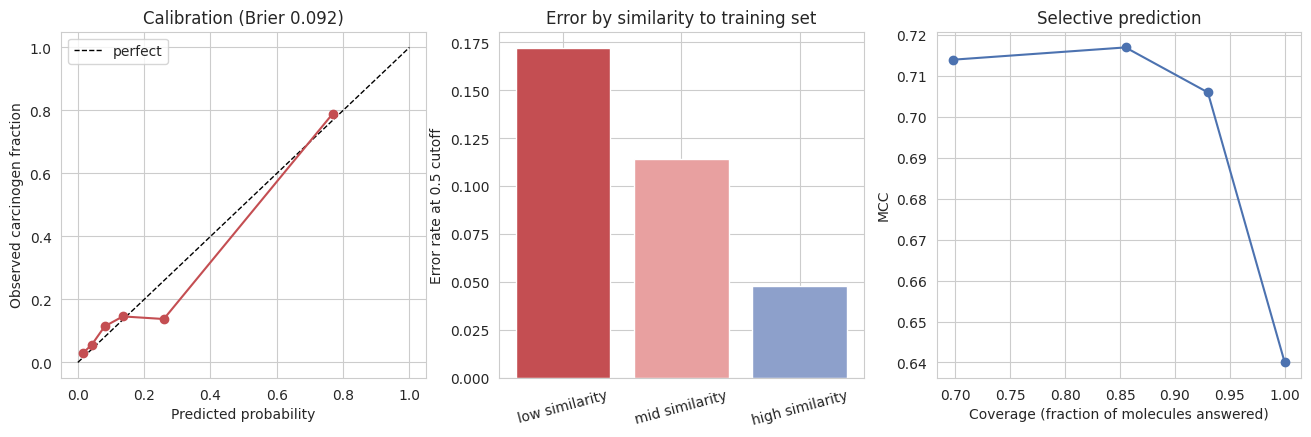

In [33]:
#@title 8.1 Calibration, applicability domain, selective prediction { display-mode: "form" }
import pickle, numpy as np, pandas as pd, matplotlib.pyplot as plt
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator
from sklearn.metrics import brier_score_loss, matthews_corrcoef, roc_auc_score, balanced_accuracy_score
from sklearn.calibration import calibration_curve

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [gen.GetFingerprint(m) for m in mols]
pool = pickle.load(open(f'{ROOT}/results/s3_oof_predictions.pkl', 'rb'))

# Pool the 5 repeats of MACCS+RF scaffold-CV out-of-fold predictions; record
# each molecule's max Tanimoto similarity to ITS OWN fold's training set.
S, Y, SIM = [], [], []
for rep in range(5):
    d = pool[('scaffold', 'MACCS', 'RandomForest', rep)]
    idx, s = np.array(d['idx']), np.array(d['s'])
    sim = np.zeros(len(y))
    for r in [r for r in scaf_cv if r['repeat'] == rep]:
        trf = [fps[j] for j in r['train']]
        for i in r['test']:
            sim[i] = max(DataStructs.BulkTanimotoSimilarity(fps[i], trf))
    S.append(s); Y.append(y[idx]); SIM.append(sim[idx])
S, Y, SIM = map(np.concatenate, (S, Y, SIM))
print(f'Pooled predictions: {len(S)} (5 repeats x 274 molecules; repeats are not independent)')

# 1) Calibration
brier = brier_score_loss(Y, S); brier_base = Y.mean() * (1 - Y.mean())
frac, mean_pred = calibration_curve(Y, S, n_bins=6, strategy='quantile')
print(f'\n[1] Brier score = {brier:.3f} (constant-prevalence predictor = {brier_base:.3f}; lower is better)')
print('    predicted prob -> observed carcinogen fraction:')
for a, b in zip(mean_pred, frac): print(f'      {a:.2f} -> {b:.2f}')

# 2) Applicability domain: performance by similarity to training set (tertiles)
q = np.quantile(SIM, [1 / 3, 2 / 3]); bins = np.digitize(SIM, q)
rows = []
for b, name in enumerate(['low similarity', 'mid similarity', 'high similarity']):
    m = bins == b; pred = (S[m] >= 0.5).astype(int)
    rows.append(dict(bin=name, sim_range=f'{SIM[m].min():.2f}-{SIM[m].max():.2f}', n=int(m.sum()),
                     carcinogen_rate=round(Y[m].mean(), 3), error_rate=round((pred != Y[m]).mean(), 3),
                     MCC=round(matthews_corrcoef(Y[m], pred), 3), AUROC=round(roc_auc_score(Y[m], S[m]), 3)))
ad = pd.DataFrame(rows); ad.to_csv(f'{ROOT}/results/s8_applicability_domain.csv', index=False)
print('\n[2] Performance by max-Tanimoto similarity to the training set:'); print(ad.to_string(index=False))

# 3) Selective prediction: answer only when confident (confidence = |p - 0.5| * 2)
conf = np.abs(S - 0.5) * 2; rows = []
for cut in [0.0, 0.3, 0.5, 0.7]:
    m = conf >= cut; pred = (S[m] >= 0.5).astype(int)
    rows.append(dict(min_confidence=cut, coverage=round(m.mean(), 3), n=int(m.sum()),
                     MCC=round(matthews_corrcoef(Y[m], pred), 3), BalAcc=round(balanced_accuracy_score(Y[m], pred), 3),
                     error_rate=round((pred != Y[m]).mean(), 3)))
sp = pd.DataFrame(rows); sp.to_csv(f'{ROOT}/results/s8_selective_prediction.csv', index=False)
print('\n[3] Selective prediction (keep only confident predictions):'); print(sp.to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].plot([0, 1], [0, 1], 'k--', lw=1, label='perfect'); ax[0].plot(mean_pred, frac, 'o-', color='#C44E52')
ax[0].set_xlabel('Predicted probability'); ax[0].set_ylabel('Observed carcinogen fraction'); ax[0].set_title(f'Calibration (Brier {brier:.3f})'); ax[0].legend()
ax[1].bar(ad.bin, ad.error_rate, color=['#C44E52', '#E8A0A0', '#8DA0CB']); ax[1].set_ylabel('Error rate at 0.5 cutoff')
ax[1].set_title('Error by similarity to training set'); ax[1].tick_params(axis='x', rotation=15)
ax[2].plot(sp.coverage, sp.MCC, 'o-', color='#4C72B0'); ax[2].set_xlabel('Coverage (fraction of molecules answered)')
ax[2].set_ylabel('MCC'); ax[2].set_title('Selective prediction')
save_fig(fig, 's8_uncertainty'); plt.show()

In [34]:
#@title 8.2 Save + download Section 8 outputs { display-mode: "form" }
package_section('section8_uncertainty', [
    *glob.glob(f'{ROOT}/results/s8_*'),
    *glob.glob(f'{ROOT}/figures/s8_*.png'),
])

Packaged: /content/drive/MyDrive/AI IN DRUG DISCOVERY/MINI PROJECT/downloads/section8_uncertainty.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
#@title 9.1 Follow-ups: epoxide check + narrowed Michael acceptor (post-hoc) { display-mode: "form" }
import pandas as pd, numpy as np
from rdkit import Chem, RDLogger
from scipy.stats import fisher_exact
RDLogger.DisableLog('rdApp.*')

df = pd.read_csv(f'{ROOT}/splits/holdout_splits.csv'); y = df.label.values
mols = [Chem.MolFromSmiles(s) for s in df.smiles_can]
A = pd.read_csv(f'{ROOT}/results/s6_alert_matrix.csv')

sel = A['Epoxide / aziridine'] == 1
print('Molecules matching "Epoxide / aziridine":')
for s, l in zip(A.smiles[sel], A.label[sel]):
    print(f'  label={l}  {s}')

NARROW = {
    'Michael acceptor, narrow A (terminal acrylic/enone)': '[CH2;!a]=[CX3;!a]-[CX3]=O',
    'Michael acceptor, narrow B (acyclic enone/enal)':     '[CX3;!a;!R]=[CX3;!a;!R]-[CX3;!R](=O)[#6,#1]',
}
rows = []
for name, sma in NARROW.items():
    p = Chem.MolFromSmarts(sma)
    hit = np.array([m.HasSubstructMatch(p) for m in mols])
    n, c = int(hit.sum()), int(y[hit].sum())
    pv = fisher_exact([[c, n - c], [y.sum() - c, (len(y) - y.sum()) - (n - c)]], alternative='greater')[1] if n else np.nan
    rows.append(dict(alert=name, n=n, carcinogens=c, carc_rate=round(c / n, 3) if n else np.nan, p_one_sided=round(pv, 4) if n else np.nan))
    if 0 < n <= 15:
        print(f'\n{name}: matched molecules')
        for s, l in zip(df.smiles_can[hit], y[hit]):
            print(f'  label={l}  {s}')
out = pd.DataFrame(rows)
out.to_csv(f'{ROOT}/results/s9_michael_narrow.csv', index=False)
print('\n', out.to_string(index=False))
print('\nOriginal (broad) pattern for comparison: n=35, carcinogens=3, rate=0.086')

Molecules matching "Epoxide / aziridine":
  label=0  C=C(C)C1C2OC(=O)C1C1(O)CC3OC34C(=O)OC2C14C
  label=0  COC1CC(OC2C(C)C(=O)OC(C)C(C)C(O)C(C)C(=O)C3(CO3)CC(C)C(OC3OC(C)CC(N(C)C)C3O)C2C)OC(C)C1O
  label=0  C[N+]1([O-])C2CC(OC(=O)C(CO)c3ccccc3)CC1C1OC12
  label=0  C=C1C(=O)OC2C1CCC(C)=CCCC1(C)OC21

Michael acceptor, narrow A (terminal acrylic/enone): matched molecules
  label=0  C=C1C(=O)OC2C1CCC(C)=CCCC1(C)OC21
  label=0  C=C(NC(=O)C(=C)NC(=O)c1csc(C2=NC3c4csc(n4)C4NC(=O)c5csc(n5)C(C(C)(O)C(C)O)NC(=O)C5CSC(=N5)C(=CC)NC(=O)C(C(C)O)NC(=O)c5csc(n5)C3(CC2)NC(=O)C(C)NC(=O)C(=C)NC(=O)C(C)NC(=O)C(C(C)CC)NC2C=Cc3c(C(C)O)cc(nc3C2O)C(=O)OC4C)n1)C(N)=O

                                               alert  n  carcinogens  carc_rate  p_one_sided
Michael acceptor, narrow A (terminal acrylic/enone)  2            0        0.0          1.0
    Michael acceptor, narrow B (acyclic enone/enal)  0            0        NaN          NaN

Original (broad) pattern for comparison: n=35, carcinogens=3, rate=0.0

In [36]:
#@title 9.2 Assemble SUBMISSION folder (predict.py, README, requirements, checkpoints) { display-mode: "form" }
import shutil, os
SUB = f'{ROOT}/SUBMISSION'
for d in ['model code', 'splits', 'checkpoints', 'data', 'results', 'figures']:
    os.makedirs(f'{SUB}/{d}', exist_ok=True)
shutil.copytree(f'{ROOT}/splits', f'{SUB}/splits', dirs_exist_ok=True)
shutil.copytree(f'{ROOT}/models', f'{SUB}/checkpoints', dirs_exist_ok=True)
shutil.copytree(f'{ROOT}/results', f'{SUB}/results', dirs_exist_ok=True)
shutil.copytree(f'{ROOT}/figures', f'{SUB}/figures', dirs_exist_ok=True)
for f in ['curated_carcinogens.csv', 'curated_carcinogens_with_props.csv', 'raw_carcinogens_lagunin.csv']:
    shutil.copy(f'{ROOT}/data/{f}', f'{SUB}/data/{f}')

# pinned requirements (now includes torch + joblib)
write_requirements(['rdkit', 'PyTDC', 'scikit-learn', 'xgboost', 'numpy', 'pandas', 'matplotlib',
                    'seaborn', 'scipy', 'joblib', 'torch'])
shutil.copy(f'{ROOT}/requirements.txt', f'{SUB}/requirements.txt')

PREDICT_PY = r'''"""Research-use carcinogenicity screening: MACCS keys + Random Forest trained on 274 curated
TDC Carcinogens_Lagunin molecules.  Educational / research use only; not for regulatory or clinical decisions.

Usage:
  python predict.py --smiles "CCNN" "c1ccccc1N"
  python predict.py --csv input.csv --col smiles --out predictions.csv
"""
import argparse
from pathlib import Path
import numpy as np, pandas as pd, joblib
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import MACCSkeys, rdFingerprintGenerator
from rdkit.Chem.MolStandardize import rdMolStandardize
RDLogger.DisableLog("rdApp.*")

ROOT = Path(__file__).resolve().parent.parent
MODEL_PATH = ROOT / "checkpoints" / "final_MACCS_RandomForest.joblib"
TRAIN_PATH = ROOT / "data" / "curated_carcinogens.csv"
SIM_LOW, SIM_HIGH = 0.24, 0.35   # similarity tertile boundaries from cross-validation (Section 8)

_chooser = rdMolStandardize.LargestFragmentChooser()
_uncharger = rdMolStandardize.Uncharger()
_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)


def standardize(smi):
    m = Chem.MolFromSmiles(str(smi))
    if m is None:
        return None
    try:
        m = _uncharger.uncharge(_chooser.choose(m))
        Chem.SanitizeMol(m)
        if not any(a.GetSymbol() == "C" for a in m.GetAtoms()):
            return None
        return Chem.MolToSmiles(m, isomericSmiles=False)
    except Exception:
        return None


def predict(smiles_list):
    model = joblib.load(MODEL_PATH)
    tr = pd.read_csv(TRAIN_PATH)
    train_set = set(tr.smiles_can)
    train_fps = [_gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in tr.smiles_can]
    rows = []
    for raw in smiles_list:
        can = standardize(raw)
        if can is None:
            rows.append(dict(input=raw, canonical=None, p_carcinogen=np.nan, call="invalid input",
                             nearest_train_similarity=np.nan, reliability="n/a",
                             note="could not parse, or not an organic molecule"))
            continue
        m = Chem.MolFromSmiles(can)
        x = np.array(list(MACCSkeys.GenMACCSKeys(m)), dtype=np.float32).reshape(1, -1)
        p = float(model.predict_proba(x)[0, 1])
        sim = float(max(DataStructs.BulkTanimotoSimilarity(_gen.GetFingerprint(m), train_fps)))
        rel = "higher" if sim >= SIM_HIGH else ("medium" if sim >= SIM_LOW else "lower")
        note = "molecule is in the training set; prediction is not independent" if can in train_set else ""
        rows.append(dict(input=raw, canonical=can, p_carcinogen=round(p, 3),
                         call="carcinogen" if p >= 0.5 else "non-carcinogen",
                         nearest_train_similarity=round(sim, 3), reliability=rel, note=note))
    return pd.DataFrame(rows)


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--smiles", nargs="*", default=[])
    ap.add_argument("--csv"); ap.add_argument("--col", default="smiles"); ap.add_argument("--out")
    a = ap.parse_args()
    smi = list(a.smiles)
    if a.csv:
        smi += pd.read_csv(a.csv)[a.col].tolist()
    res = predict(smi)
    print(res.to_string(index=False))
    if a.out:
        res.to_csv(a.out, index=False)
    print("\nResearch use only. Reliability is lower when the nearest training molecule is dissimilar.")
'''
open(f'{SUB}/model code/predict.py', 'w').write(PREDICT_PY)

README = r'''# Carcinogenicity Prediction from Chemical Structure (Challenge 59, AI in Drug Discovery)

Team: [TEAM NAMES]  |  Dataset: TDC `Carcinogens_Lagunin` (carcinogen vs non-carcinogen)  |  Research / educational use only.

## Data
- 280 raw molecules -> 274 after curation (largest fragment, uncharge, canonical non-stereo SMILES; 2 molecules with conflicting labels removed; 2 duplicate rows collapsed). 58 carcinogens / 216 non-carcinogens (21.2%).
- TDC's own official split shares molecules between sets (1 train/test, 3 train/valid after standardization); ours was built after de-duplication and passes a leakage audit.

## Splits (`splits/`)
Repeated 5x5 stratified CV (random), 5x5 scaffold-grouped CV (each acyclic molecule is its own group), 5x5 cluster CV (Butina, Tanimoto >= 0.4), and fixed scaffold / random train-valid-test holdouts. Audit: no shared molecules, and no shared scaffolds / clusters in the grouped splits.

## Headline results (MCC, mean +/- sd over 5 repeats of pooled out-of-fold predictions)
| Model | Scaffold CV | Random CV | Cluster CV |
|---|---|---|---|
| MACCS + Random Forest | 0.640 +/- 0.021 | 0.654 +/- 0.021 | 0.602 +/- 0.041 |
| RDKit descriptors + SVM | 0.624 +/- 0.031 | 0.636 +/- 0.029 | 0.557 +/- 0.056 |
| Morgan counts + Random Forest | 0.622 +/- 0.015 | 0.630 +/- 0.025 | 0.553 +/- 0.006 |
| GIN ensemble (2 seeds) | 0.503 +/- 0.022 | 0.512 +/- 0.069 | not run |

- Classical fingerprint models beat the small GNN on every split with this data size (paired difference about -0.14 MCC on scaffold and random CV, negative in all 5 repeats).
- Label-shuffling sanity test: shuffled-label MCC is about 0 (max +0.117) versus about 0.62 for real labels.
- Performance leans on two analog series (aromatic azo dyes, alkyl hydrazines; 23 molecules, 22 carcinogens). Without them MCC is about 0.42-0.45 and AUROC about 0.77-0.82 (indicative; fewer carcinogens lowers MCC by itself).
- Error rate by similarity to training set: about 17% (low), 11% (mid), 5% (high).

## Reproduce
1. `pip install -r requirements.txt` (PyTDC was installed with `pip install PyTDC --no-deps` on Colab to avoid a build failure).
2. Run the notebook in `model code/` top to bottom (Sections 0-9); it regenerates data, splits, models, results, figures.
3. Score new molecules: `python "model code/predict.py" --smiles "CCNN"`

## Checkpoints
`checkpoints/final_*` were trained on ALL 274 molecules. Report performance only from the CV / holdout results in `results/`, never from these final models.

## Limitations
Small dataset (about 270 molecules, 58 positives); heavy reliance on two chemical series; scaffold CV is mildly optimistic versus cluster CV; fixed-hyperparameter baselines; GNN untuned; structural-alert SMARTS written by us and not yet verified against the primary literature; no experimental validation. Not for regulatory or clinical use.

## AI assistance acknowledgement
Code and analysis planning were assisted by Claude (Anthropic). Scientific decisions, interpretation and conclusions are the team's.
'''
open(f'{SUB}/README.md', 'w').write(README)
print('SUBMISSION folder ready:'); print(sorted(os.listdir(SUB)))

rdkit==2026.3.6
PyTDC==1.1.15
scikit-learn==1.6.1
xgboost==3.4.1
numpy==2.1.3
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2
scipy==1.16.3
joblib==1.6.0
torch==2.11.0+cu130
SUBMISSION folder ready:
['README.md', 'checkpoints', 'data', 'figures', 'model code', 'requirements.txt', 'results', 'splits']


In [37]:
#@title 9.3 Test predict.py { display-mode: "form" }
import subprocess, sys
r = subprocess.run([sys.executable, f'{SUB}/model code/predict.py', '--smiles',
                    'CCNN', 'Nc1ccc(cc1)N=Nc1ccccc1', 'CC(=O)Nc1ccc(O)cc1', 'CCO', 'not_a_smiles'],
                   capture_output=True, text=True)
print(r.stdout); print(r.stderr[-1500:])

                 input              canonical  p_carcinogen           call  nearest_train_similarity reliability                                                           note
                  CCNN                   CCNN         0.990     carcinogen                     1.000      higher molecule is in the training set; prediction is not independent
Nc1ccc(cc1)N=Nc1ccccc1 Nc1ccc(N=Nc2ccccc2)cc1         0.774     carcinogen                     0.327      medium                                                               
    CC(=O)Nc1ccc(O)cc1     CC(=O)Nc1ccc(O)cc1         0.216 non-carcinogen                     0.308      medium                                                               
                   CCO                    CCO         0.668     carcinogen                     0.250      medium                                                               
          not_a_smiles                   None           NaN  invalid input                       NaN         n/a        

In [38]:
#@title 9.4 Download SUBMISSION package { display-mode: "form" }
package_section('SUBMISSION_v1', [SUB])

Packaged: /content/drive/MyDrive/AI IN DRUG DISCOVERY/MINI PROJECT/downloads/SUBMISSION_v1.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>